# Task 3 – Đọc chuỗi chữ số viết tay từ ảnh (Image-to-Sequence)

**Bài toán.** Đầu vào là một ảnh xám 32 × 256 chứa một dãy 3–8 chữ số viết tay. Đầu ra là chuỗi chữ số trong ảnh, ví dụ `"20369"` (giữ cả số 0 ở đầu).

**Mô hình chính.** CNN encoder gồm các khối kiểu VGG (chương 5.2) biến ảnh thành một dãy 64 vector cột xếp từ trái sang phải; một lớp BiLSTM (chương 7) cho mỗi cột biết ngữ cảnh hai bên; LSTM decoder (chương 8) sinh lần lượt từng chữ số cho tới khi gặp `<eos>`. Ở mỗi bước, cơ chế attention cộng (Bahdanau) chấm điểm 64 cột để decoder tự tìm dải ảnh chứa chữ số cần đọc.

**Các bước thực hiện**
1. Đọc bộ ảnh v3 (mỗi ảnh là một dãy 3–8 chữ số của **cùng một người viết**; 20.000 / 2.000 / 2.000), chuẩn hoá ảnh, mã hoá nhãn thành dãy token (`04_task3_data.ipynb` mô tả chi tiết dữ liệu).
2. Xây mô hình; huấn luyện bằng teacher forcing, cross-entropy bỏ qua `<pad>`, Adam, tăng cường dữ liệu và dừng sớm theo tỷ lệ đọc đúng cả chuỗi trên validation.
3. Đọc kết quả bằng greedy search và beam search (chương 8).
4. Đánh giá trên tập test bằng R², NSE, MAE, RMSE (hai cách quy chuỗi thành số) cùng các chỉ số nhận dạng chuỗi: độ chính xác cả chuỗi, CER, độ chính xác độ dài.
5. Trực quan hoá attention, phân tích lỗi (ma trận nhầm lẫn, đọc kèm độ tự tin).
6. Thí nghiệm: so sánh 4 kiến trúc (E6), greedy và beam search (E7), độ ổn định qua 3 seed và gộp 3 seed, ghép chuỗi từ nhiều người viết (v2, cách cũ) hay một người viết (v3), sinh thêm dữ liệu (20.000 so với 60.000 ảnh train), tăng cường dữ liệu mạnh hơn; cuối cùng kiểm tra các chênh lệch bằng khoảng tin cậy bootstrap.

Notebook dùng Keras 3 (`keras.layers`, `keras.ops`) nên chạy được với backend TensorFlow (mặc định trên Colab) lẫn PyTorch. Kết quả bên dưới được chạy trên MacBook Apple M4 Pro với backend PyTorch (GPU Apple, MPS); nhóm đã kiểm tra: nạp cùng file trọng số vào backend TensorFlow cho đúng các dự đoán và chỉ số như vậy. Trọng số đã huấn luyện được lưu trong `task3_outputs/models`; chạy lại notebook sẽ đọc trọng số có sẵn thay vì huấn luyện lại (đặt `RETRAIN = True` để huấn luyện lại từ đầu).

## 1. Cài đặt

In [1]:
# !unzip -q FinalDeepData_hoan_chinh.zip      # chỉ cần trên Colab
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")   # Colab dùng TensorFlow; có thể đổi thành "torch" hoặc "jax"

import sys, json, time, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import keras
from keras import layers, ops

DATA_ROOT = "FinalDeepData"
sys.path.append(os.path.join(DATA_ROOT, "common"))
from data_utils import load_task3, encode_labels, decode_tokens, augment, PAD, BOS, EOS, VOCAB_SIZE
import metrics      # R², NSE, MAE, RMSE theo slide chương 2.1 + chỉ số cho chuỗi

OUT_DIR = "task3_outputs"
FIG_DIR, MODEL_DIR, RESULT_DIR = [os.path.join(OUT_DIR, d) for d in ("figures", "models", "results")]
for d in (FIG_DIR, MODEL_DIR, RESULT_DIR):
    os.makedirs(d, exist_ok=True)

print("Keras", keras.__version__, "| backend:", keras.backend.backend())

Keras 3.15.1 | backend: torch


In [2]:
# ---- Siêu tham số (proposal mục 5.3) ----
SEED = 42
BATCH_SIZE = 64
EPOCHS = 30              # tối đa 30 epoch
PATIENCE = 5             # dừng sớm nếu độ chính xác cả chuỗi trên validation không tăng sau 5 epoch
LEARNING_RATE = 1e-3     # Adam
RETRAIN = False          # True: huấn luyện lại kể cả khi đã có trọng số lưu sẵn
RUN_EXPERIMENTS = True   # False: chỉ huấn luyện và đánh giá mô hình chính

MAX_LEN = 8              # chuỗi dài nhất có 8 chữ số
T_DEC = MAX_LEN + 1      # số bước của decoder: 8 chữ số + <eos>
IMG_H, IMG_W = 32, 256
N_COLS = IMG_W // 4      # 64 cột sau hai lần MaxPool 2x2 theo chiều ngang
TOKEN_NAMES = [str(d) for d in range(10)] + ["<pad>", "<bos>", "<eos>"]

# Kiểu hình vẽ: lưới mờ, bỏ viền trên/phải; màu theo thứ tự cố định
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e"})
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

## 2. Dữ liệu

Bộ chính là **v3**: mỗi ảnh ghép 3–8 chữ số MNIST của **cùng một người viết** (mã người viết lấy từ QMNIST), kiểu chữ chọn chung cho cả chuỗi, chữ số sát hoặc chồng nhẹ, xoay, nghiêng, mờ. Bộ v2 (cách ghép cũ: mỗi chữ số lấy từ một ảnh MNIST bất kỳ, nên một chuỗi là chữ của nhiều người) chỉ dùng ở mục 11 để so sánh. Mỗi bộ có 20.000 ảnh train, 2.000 ảnh validation, 2.000 ảnh test. Ở v3, ba tập dùng ba nhóm người viết khác nhau, nên validation và test đều là chữ của người mà mô hình chưa gặp khi huấn luyện.

`load_task3` đọc nhãn dạng chuỗi (giữ số 0 ở đầu) và đệm nền đen bên phải cho đủ 32 × 256. `encode_labels` tạo hai dãy token cho decoder:
- đầu vào decoder: `<bos>` d1 … dn `<pad>` …
- đích cần dự đoán: d1 … dn `<eos>` `<pad>` …

In [3]:
TASK3_DATA = os.path.join(DATA_ROOT, "task3", "data")
V3_DIR = os.path.join(TASK3_DATA, "mnist_sequences_v3")
V2_DIR = os.path.join(TASK3_DATA, "mnist_sequences_v2")
if not os.path.exists(V3_DIR):                                # chưa có bộ v3 thì sinh (khoảng 20 giây)
    subprocess.run([sys.executable, "generate_data_v3.py"], cwd=os.path.join(DATA_ROOT, "task3"), check=True)


def load_split(root, split):
    X, labels = load_task3(root, split)                       # X: (N, 32, 256) uint8
    dec_in, dec_out = encode_labels(labels, max_len=MAX_LEN)  # (N, 9) mỗi mảng
    return {"X": X, "labels": labels, "dec_in": dec_in, "dec_out": dec_out}


data = {}
for version, root in [("v3", V3_DIR), ("v2", V2_DIR)]:
    if not os.path.exists(root):                              # bộ v2 cũ chỉ cần cho mục 11
        print(f"Không có {root}: bỏ qua mục 11 (so sánh với bộ v2 cũ)")
        continue
    for split in ["train", "validation", "test"]:
        data[version, split] = load_split(root, split)
        print(f"{version} {split:<10} X {data[version, split]['X'].shape}  ví dụ nhãn: {data[version, split]['labels'][:3]}")

v3 train      X (20000, 32, 256)  ví dụ nhãn: ['335790', '094162', '372']


v3 validation X (2000, 32, 256)  ví dụ nhãn: ['59634', '61403', '8100768']


v3 test       X (2000, 32, 256)  ví dụ nhãn: ['01606562', '4848', '85998639']


v2 train      X (20000, 32, 256)  ví dụ nhãn: ['013204', '3063', '1286611']


v2 validation X (2000, 32, 256)  ví dụ nhãn: ['335273', '60113600', '7539523']


v2 test       X (2000, 32, 256)  ví dụ nhãn: ['7200', '86968', '02931']


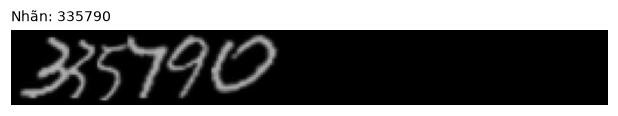

Đầu vào decoder: ['<bos>', '3', '3', '5', '7', '9', '0', '<pad>', '<pad>']
Đích cần dự đoán: ['3', '3', '5', '7', '9', '0', '<eos>', '<pad>', '<pad>']


In [4]:
def to_float(X):
    # uint8 (N, 32, 256) -> float32 (N, 32, 256, 1), giá trị trong [0, 1]
    return (X.astype("float32") / 255.0)[..., None]


d = data["v3", "train"]
fig, ax = plt.subplots(figsize=(7, 1.2))
ax.imshow(d["X"][0], cmap="gray", vmin=0, vmax=255)
ax.set_title(f"Nhãn: {d['labels'][0]}", fontsize=9, loc="left")
ax.axis("off")
plt.show()
print("Đầu vào decoder:", [TOKEN_NAMES[t] for t in d["dec_in"][0]])
print("Đích cần dự đoán:", [TOKEN_NAMES[t] for t in d["dec_out"][0]])

### Tăng cường dữ liệu khi huấn luyện (chương 5.3)

Mỗi batch train được biến đổi ngẫu nhiên lại bằng hàm `augment` (đổi độ sáng, thêm nhiễu Gauss), nên qua các epoch mô hình gần như không thấy cùng một ảnh hai lần. Lớp `DigitSeqDataset` (kế thừa `keras.utils.PyDataset`) cắt batch, tăng cường ảnh và xáo trộn lại thứ tự sau mỗi epoch. Tập validation và test không bị biến đổi.

In [5]:
class DigitSeqDataset(keras.utils.PyDataset):
    def __init__(self, X, dec_in, dec_out, batch_size=64, shuffle=True, augment_images=False, seed=0,
                 augment_fn=None, **kwargs):
        super().__init__(**kwargs)
        self.X, self.dec_in, self.dec_out = X, dec_in, dec_out
        self.batch_size, self.shuffle, self.augment_images = batch_size, shuffle, augment_images
        self.augment_fn = augment if augment_fn is None else augment_fn   # mặc định: augment của data_utils
        self.rng = np.random.default_rng(seed)
        self.order = np.arange(len(X))
        if shuffle:
            self.rng.shuffle(self.order)

    def __len__(self):
        return int(np.ceil(len(self.X) / self.batch_size))

    def __getitem__(self, i):
        idx = self.order[i * self.batch_size:(i + 1) * self.batch_size]
        x = self.X[idx]
        if self.augment_images:
            x = self.augment_fn(x, self.rng)   # mặc định: độ sáng + nhiễu; nhãn giữ nguyên
        x = to_float(x)
        # Mô hình seq2seq nhận (ảnh, đầu vào decoder); mô hình mốc chỉ nhận ảnh
        inputs = x if self.dec_in is None else (x, self.dec_in[idx])
        return inputs, self.dec_out[idx]

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.order)

## 3. Mô hình

### 3.1. CNN encoder: biến ảnh thành dãy 64 vector cột

Nhóm coi ảnh như một câu: CNN đọc ảnh và trả về một dãy vector xếp từ trái sang phải, mỗi vector mô tả một dải dọc hẹp của ảnh. Từ đó bài toán giống dịch máy ở chương 8: encoder có một dãy đầu vào, decoder sinh một dãy đầu ra.

| Khối | Cấu hình | Kích thước đầu ra |
|---|---|---|
| Đầu vào | Ảnh xám, chia 255 về [0, 1] | 32 × 256 × 1 |
| Khối 1 | Conv 3×3, 32 kênh + BatchNorm + ReLU; MaxPool 2×2 | 16 × 128 × 32 |
| Khối 2 | Conv 3×3, 64 kênh + BatchNorm + ReLU; MaxPool 2×2 | 8 × 64 × 64 |
| Khối 3 | 2 × (Conv 3×3, 128 kênh + BatchNorm + ReLU); MaxPool 2×1 | 4 × 64 × 128 |
| Khối 4 | 2 × (Conv 3×3, 256 kênh + BatchNorm + ReLU); MaxPool 2×1 | 2 × 64 × 256 |
| Chuyển thành dãy | Mỗi cột gộp thành 2 × 256 = 512 số → Dense 256 + ReLU, Dropout 0,2 | 64 bước × 256 |
| BiLSTM | 128 unit mỗi chiều, nối hai chiều | 64 bước × 256 |

- **Khối kiểu VGG (chương 5.2):** các lớp Conv 3×3 xếp thành khối rồi MaxPool. Số lớp conv mỗi khối (1, 1, 2, 2) giống bốn khối đầu của VGG-11, số kênh bằng một nửa vì ảnh nhỏ và chỉ có một kênh màu. BatchNorm sau mỗi lớp conv giúp huấn luyện ổn định (chương 4.3).
- **Hai khối cuối chỉ giảm chiều cao (MaxPool 2×1)** để giữ 64 cột theo chiều ngang: mỗi cột ứng với một dải rộng 4 pixel. Chuỗi 8 chữ số thì mỗi chữ số chiếm khoảng 2,5–8 cột, đủ để attention chỉ đúng vị trí. (Proposal dự kiến ảnh 48 × 384 và 96 cột; bộ dữ liệu cuối cùng có ảnh 32 × 256 nên còn 64 cột.)
- **BiLSTM (chương 7):** CNN chỉ nhìn một vùng hẹp quanh mỗi cột (khoảng 42 pixel). BiLSTM đọc 64 cột theo cả hai chiều nên mỗi cột biết thêm ngữ cảnh hai bên, ví dụ "đây là chữ số thứ mấy tính từ trái". Trạng thái cuối của hai chiều được nối lại làm trạng thái ban đầu của decoder, đúng như slide chương 8.

In [6]:
# (số lớp conv, số kênh, kích thước MaxPool) của từng khối
CONV_ARCH = ((1, 32, (2, 2)), (1, 64, (2, 2)), (2, 128, (2, 1)), (2, 256, (2, 1)))


def vgg_block(x, num_convs, num_channels, pool_size):
    # Khối VGG (chương 5.2): các lớp Conv 3x3 + BatchNorm + ReLU, rồi MaxPool
    for _ in range(num_convs):
        x = layers.Conv2D(num_channels, (3, 3), padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    return layers.MaxPooling2D(pool_size=pool_size)(x)


def cnn_columns(img):
    x = img
    for num_convs, num_channels, pool in CONV_ARCH:
        x = vgg_block(x, num_convs, num_channels, pool)    # -> (2, 64, 256)
    x = layers.Permute((2, 1, 3))(x)                       # (64, 2, 256): đưa chiều rộng lên trước
    x = layers.Reshape((N_COLS, 2 * 256))(x)               # (64, 512): 64 cột từ trái sang phải
    x = layers.Dense(256, activation="relu")(x)            # (64, 256)
    return layers.Dropout(0.2)(x)


def build_encoder(use_bilstm=True, units=256):
    # Trả về: H (dãy 64 vector để attention nhìn vào) và trạng thái ban đầu [h0, c0] của decoder
    img = keras.Input(shape=(IMG_H, IMG_W, 1), name="image")
    cols = cnn_columns(img)
    if use_bilstm:
        H, fh, fc, bh, bc = layers.Bidirectional(
            layers.LSTM(units // 2, return_sequences=True, return_state=True))(cols)
        h0 = layers.Concatenate()([fh, bh])                # trạng thái cuối của hai chiều
        c0 = layers.Concatenate()([fc, bc])
    else:
        H = cols                                           # không có BiLSTM: dùng thẳng các cột CNN
        g = layers.GlobalAveragePooling1D()(cols)
        h0 = layers.Dense(units, activation="tanh")(g)
        c0 = layers.Dense(units, activation="tanh")(g)
    return keras.Model(img, [H, h0, c0], name="encoder")


build_encoder().summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 32, 256,   │          0 │ -                 │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 256,   │        320 │ image[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32, 256,   │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 256,   │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 16, 128,   │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 16, 128,   │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 128,   │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 16, 128,   │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 8, 64, 64) │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 8, 64,     │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 64,     │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 8, 64,     │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 8, 64,     │    147,584 │ activation_2[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 64,     │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 8, 64,     │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 4, 64,     │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 4, 64,     │    295,168 │ max_pooling2d_2[

 Total params: 1,654,528 (6.31 MB)

 Trainable params: 1,652,800 (6.30 MB)

 Non-trainable params: 1,728 (6.75 KB)

### 3.2. Cơ chế attention cộng (Bahdanau)

Seq2seq ở slide chương 8 nén cả đầu vào thành **một** vector ngữ cảnh $c$ cố định. Với ảnh 8 chữ số, một vector khó giữ đủ thông tin từng chữ số. Attention cho decoder ở mỗi bước $t$ nhìn lại cả 64 vector $h_1, \dots, h_{64}$ và tự chọn cột quan trọng (Bahdanau và cộng sự, 2015):

$$e_{t,i} = v^\top \tanh(W h_i + U s_{t-1}), \qquad \alpha_{t,i} = \frac{\exp(e_{t,i})}{\sum_{j=1}^{64} \exp(e_{t,j})}, \qquad c_t = \sum_{i=1}^{64} \alpha_{t,i} h_i$$

- $s_{t-1}$: trạng thái của decoder ở bước trước, đóng vai "câu hỏi": tôi cần đọc chữ số nào tiếp theo?
- $e_{t,i}$: điểm cho biết cột $i$ liên quan bao nhiêu; softmax đổi điểm thành trọng số $\alpha_{t,i}$ có tổng bằng 1.
- $c_t$: vector ngữ cảnh riêng của bước $t$, là tổng có trọng số của các cột.
- $W$, $U$, $v$ là tham số học được (ba lớp Dense). Phần $W h_i$ không phụ thuộc bước $t$ nên chỉ tính một lần cho mỗi ảnh.

In [7]:
class BahdanauAttention(layers.Layer):
    # e_i = v^T tanh(W h_i + U s),  alpha = softmax(e),  c = sum_i alpha_i h_i
    def __init__(self, units, **kwargs):
        super().__init__(**kwargs)
        self.W = layers.Dense(units, use_bias=False)
        self.U = layers.Dense(units)
        self.v = layers.Dense(1, use_bias=False)

    def call(self, s, H, WH=None):
        if WH is None:
            WH = self.W(H)                                          # (B, 64, units)
        e = self.v(ops.tanh(WH + ops.expand_dims(self.U(s), 1)))    # (B, 64, 1): điểm từng cột
        alpha = ops.softmax(e, axis=1)                              # trọng số, tổng bằng 1
        context = ops.sum(alpha * H, axis=1)                        # (B, 256): vector ngữ cảnh c_t
        return context, ops.squeeze(alpha, axis=-1)

### 3.3. LSTM decoder và mô hình hoàn chỉnh

Decoder là một ô LSTM chạy tối đa 9 bước. Ở bước $t$ (giống công thức $s_{t'} = g(y_{t'-1}, c, s_{t'-1})$ ở slide chương 8, chỉ thay $c$ cố định bằng $c_t$ của attention):
1. Attention dùng trạng thái $s_{t-1}$ để tính vector ngữ cảnh $c_t$.
2. Đầu vào của LSTM là embedding (64 chiều) của token bước trước $y_{t-1}$ nối với $c_t$; LSTM cập nhật trạng thái thành $s_t$.
3. Ghép $[s_t; c_t]$, qua Dropout 0,3 và Dense 13 + softmax để ra xác suất của 13 token.

**Teacher forcing.** Khi huấn luyện, decoder nhận token **đúng** của bước trước (cột "đầu vào decoder" ở mục 2), nên cả 9 bước được tính trong một lần gọi mô hình. Khi dự đoán, decoder nhận token chính nó vừa sinh (mục 3.6).

Lớp `Img2Seq` có hai cờ để tạo các biến thể cho thí nghiệm E6:
- `use_attention=False`: bỏ attention, decoder chỉ nhận vector $c$ cố định (trạng thái cuối của encoder) ở mọi bước, đúng seq2seq của chương 8.
- `use_bilstm=False`: bỏ BiLSTM, attention nhìn thẳng vào các cột của CNN.

In [8]:
class Img2Seq(keras.Model):
    def __init__(self, use_bilstm=True, use_attention=True, units=256, emb_dim=64, att_units=128, **kwargs):
        super().__init__(**kwargs)
        self.use_attention = use_attention
        self.encoder = build_encoder(use_bilstm, units)
        self.embedding = layers.Embedding(VOCAB_SIZE, emb_dim)
        self.attention = BahdanauAttention(att_units) if use_attention else None
        self.cell = layers.LSTMCell(units)
        self.dropout = layers.Dropout(0.3)
        self.fc = layers.Dense(VOCAB_SIZE, activation="softmax")

    def init_decoder(self, images, training=False):
        H, h0, c0 = self.encoder(images, training=training)
        WH = self.attention.W(H) if self.use_attention else None   # W h_i: tính một lần cho mỗi ảnh
        return H, WH, h0, [h0, c0]          # h0 cũng là vector c cố định khi không có attention

    def step(self, y_prev, state, H, WH, c_fixed, training=False):
        # Một bước decoder: y_prev (B,) là token bước trước, state = [s_{t-1}, ô nhớ]
        if self.use_attention:
            context, alpha = self.attention(state[0], H, WH)
        else:
            context, alpha = c_fixed, None
        x = ops.concatenate([self.embedding(y_prev), context], axis=-1)
        s, state = self.cell(x, state, training=training)
        z = self.dropout(ops.concatenate([s, context], axis=-1), training=training)
        return self.fc(z), state, alpha

    def call(self, inputs, training=False):
        images, dec_in = inputs                # dec_in: <bos> d1 ... dn <pad> ... (teacher forcing)
        H, WH, c_fixed, state = self.init_decoder(images, training)
        outputs = []
        for t in range(T_DEC):
            probs, state, _ = self.step(dec_in[:, t], state, H, WH, c_fixed, training)
            outputs.append(probs)
        return ops.stack(outputs, axis=1)      # (B, 9, 13)

### 3.4. Mô hình mốc: CNN + nhiều đầu softmax (không có RNN)

Để biết phần RNN đóng góp bao nhiêu, nhóm dùng một mô hình mốc chỉ có CNN (cùng CNN encoder như trên): duỗi 64 cột thành một vector, qua Dense 512, rồi **9 đầu softmax độc lập**, đầu thứ $k$ đoán token ở vị trí $k$ của dãy đích (một chữ số hoặc `<eos>`). Vị trí của `<eos>` cho biết độ dài chuỗi, nên đây chính là cách "8 lớp softmax cho 8 vị trí + một lớp đoán độ dài" của proposal (chương 3.2), chỉ viết gọn trong cùng bộ token.

In [9]:
def build_multihead():
    img = keras.Input(shape=(IMG_H, IMG_W, 1), name="image")
    x = layers.Flatten()(cnn_columns(img))                 # 64 x 256 = 16384 số
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(T_DEC * VOCAB_SIZE)(x)
    x = layers.Reshape((T_DEC, VOCAB_SIZE))(x)              # 9 vị trí x 13 token
    out = layers.Softmax()(x)                              # softmax riêng cho từng vị trí
    return keras.Model(img, out, name="cnn_multihead")

### 3.5. Hàm mất mát và chỉ số theo dõi khi huấn luyện

- **Hàm mất mát:** ở mỗi bước decoder ra một phân phối xác suất trên 13 token (softmax), rồi dùng cross-entropy như slide chương 8. Các vị trí `<pad>` (sau `<eos>`) bị bỏ qua để chuỗi ngắn không bị "học" phần đệm:
$$\mathcal{L} = -\frac{1}{\#\{(n,t): y_{n,t} \ne \texttt{<pad>}\}} \sum_{n} \sum_{t:\, y_{n,t} \ne \texttt{<pad>}} \log P(y_{n,t} \mid y_{n,<t}, \text{ảnh}_n)$$
- **`token_acc`:** tỷ lệ token (chữ số và `<eos>`) đoán đúng.
- **`seq_acc`:** tỷ lệ ảnh mà mọi token đều đúng, tức đọc đúng cả chuỗi. Chỉ số này tính với teacher forcing nhưng **bằng đúng** tỷ lệ đọc đúng khi dùng greedy search: nếu mọi token đều đúng thì ở mỗi bước token decoder nhận vào cũng chính là token đúng, hai cách chạy trùng nhau. Vì vậy nhóm dùng `val_seq_acc` để dừng sớm.

In [10]:
def masked_loss(y_true, y_pred):
    y_true = ops.cast(y_true, "int32")
    loss = keras.losses.sparse_categorical_crossentropy(y_true, y_pred)   # (B, 9)
    mask = ops.cast(ops.not_equal(y_true, PAD), loss.dtype)              # 0 ở vị trí <pad>
    return ops.sum(loss * mask) / ops.sum(mask)


def token_acc(y_true, y_pred):
    y_true = ops.cast(y_true, "int32")
    pred = ops.cast(ops.argmax(y_pred, axis=-1), "int32")
    mask = ops.not_equal(y_true, PAD)
    correct = ops.logical_and(ops.equal(pred, y_true), mask)
    return ops.sum(ops.cast(correct, "float32")) / ops.sum(ops.cast(mask, "float32"))


def seq_acc(y_true, y_pred):
    # Trả về 1/0 cho từng ảnh; Keras lấy trung bình trên toàn bộ ảnh của tập
    y_true = ops.cast(y_true, "int32")
    pred = ops.cast(ops.argmax(y_pred, axis=-1), "int32")
    ok = ops.logical_or(ops.equal(pred, y_true), ops.equal(y_true, PAD))
    return ops.cast(ops.all(ok, axis=1), "float32")

### 3.6. Đọc kết quả: greedy search và beam search (chương 8)

- **Greedy search:** bắt đầu bằng `<bos>`; ở mỗi bước lấy token có xác suất cao nhất và đưa nó vào bước sau; dừng khi gặp `<eos>` (hoặc đủ 9 bước).
- **Beam search** với beam size $k$: bước đầu giữ $k$ token có xác suất cao nhất; mỗi bước sau, từ $k$ chuỗi ứng viên xét $k \cdot |\mathcal{Y}|$ cách nối thêm một token ($|\mathcal{Y}| = 13$) và giữ $k$ chuỗi có log-xác suất cao nhất. Chuỗi đã gặp `<eos>` thì dừng lại (phần sau `<eos>` bị bỏ). Cuối cùng chọn chuỗi có điểm cao nhất theo công thức trong sách d2l (cơ sở của slide chương 8), chia cho độ dài để không thiên vị chuỗi ngắn:
$$\text{score} = \frac{1}{L^{\alpha}} \log P(y_1, \dots, y_L \mid \text{ảnh}), \qquad \alpha = 0{,}75$$
  trong đó $L$ là số token của chuỗi tính cả `<eos>`.
- Với mô hình mốc nhiều đầu softmax, mỗi vị trí lấy token có xác suất cao nhất.

In [11]:
import contextlib


def inference_mode():
    # Khi dự đoán không cần gradient. Backend PyTorch mặc định vẫn ghi lại các phép tính để lan truyền
    # ngược (tốn nhiều bộ nhớ) nên phải tắt; backend TensorFlow không cần làm gì.
    if keras.backend.backend() == "torch":
        import torch
        return torch.no_grad()
    return contextlib.nullcontext()


def greedy_decode(model, X, batch_size=250, return_attention=False):
    preds, atts = [], []
    for i in range(0, len(X), batch_size):
        x = to_float(X[i:i + batch_size])
        if not isinstance(model, Img2Seq):                 # mô hình mốc: đoán cả 9 vị trí một lần
            tokens = model.predict(x, verbose=0).argmax(-1)
            preds += [decode_tokens(t) for t in tokens]
            continue
        with inference_mode():
            H, WH, c_fixed, state = model.init_decoder(x)
            y = ops.full((len(x),), BOS, dtype="int32")   # bước đầu: <bos>
            tokens, alphas = [], []
            for _ in range(T_DEC):
                probs, state, alpha = model.step(y, state, H, WH, c_fixed)
                y = ops.cast(ops.argmax(probs, axis=-1), "int32")   # token xác suất cao nhất -> bước sau
                tokens.append(ops.convert_to_numpy(y))
                if alpha is not None:
                    alphas.append(ops.convert_to_numpy(alpha))
        preds += [decode_tokens(t) for t in np.stack(tokens, 1)]   # dừng ở <eos>
        if alphas:
            atts.append(np.stack(alphas, 1))               # (B, 9, 64)
    if return_attention:
        return preds, np.concatenate(atts)
    return preds


def beam_search(model, X, beam_size=3, alpha=0.75, batch_size=125):
    with inference_mode():
        return _beam_search(model, X, beam_size, alpha, batch_size)


def _beam_search(model, X, beam_size, alpha, batch_size):
    V, k = VOCAB_SIZE, beam_size
    preds = []
    for i in range(0, len(X), batch_size):
        x = to_float(X[i:i + batch_size])
        B = len(x)
        H, WH, c_fixed, state = model.init_decoder(x)
        rep = ops.convert_to_tensor(np.repeat(np.arange(B), k), dtype="int32")   # mỗi ảnh lặp k lần
        H, c_fixed = ops.take(H, rep, axis=0), ops.take(c_fixed, rep, axis=0)
        WH = ops.take(WH, rep, axis=0) if WH is not None else None
        state = [ops.take(s, rep, axis=0) for s in state]
        scores = np.full((B, k), -np.inf)
        scores[:, 0] = 0.0                        # lúc đầu mỗi ảnh chỉ có một ứng viên (<bos>)
        tokens = np.zeros((B, k, 0), dtype=int)
        finished = np.zeros((B, k), dtype=bool)
        y = np.full(B * k, BOS)
        for _ in range(T_DEC):
            probs, state, _ = model.step(ops.convert_to_tensor(y, dtype="int32"), state, H, WH, c_fixed)
            logp = np.log(ops.convert_to_numpy(probs).reshape(B, k, V) + 1e-12)
            logp[finished] = -np.inf              # ứng viên đã gặp <eos> chỉ được nối <pad>, không đổi điểm
            logp[finished, PAD] = 0.0
            flat = (scores[:, :, None] + logp).reshape(B, k * V)
            top = np.argsort(-flat, axis=1)[:, :k]           # giữ k chuỗi tốt nhất trong k*|Y| cách nối
            beam_id, tok = top // V, top % V
            scores = np.take_along_axis(flat, top, axis=1)
            tokens = np.concatenate([np.take_along_axis(tokens, beam_id[:, :, None], axis=1),
                                     tok[:, :, None]], axis=2)
            finished = np.take_along_axis(finished, beam_id, axis=1) | (tok == EOS)
            gather = ops.convert_to_tensor((np.arange(B)[:, None] * k + beam_id).ravel(), dtype="int32")
            state = [ops.take(s, gather, axis=0) for s in state]      # trạng thái đi theo ứng viên
            y = tok.ravel()
        is_eos = tokens == EOS
        L = np.where(is_eos.any(-1), is_eos.argmax(-1) + 1, T_DEC)   # độ dài tính cả <eos>
        best = np.argmax(scores / L ** alpha, axis=1)
        preds += [decode_tokens(tokens[b, best[b]]) for b in range(B)]
    return preds

### 3.7. Chỉ số đánh giá: áp dụng R², NSE, MAE, RMSE cho bài toán sinh chuỗi

Với $o_i$ là giá trị thực tế, $p_i$ là giá trị dự đoán, $\bar o, \bar p$ là trung bình và $n$ là số cặp (slide chương 2.1):

$$\text{NSE} = 1 - \frac{\sum_{i}(o_i - p_i)^2}{\sum_{i}(o_i - \bar o)^2}, \qquad
\text{R}^2 = \left[\frac{\sum_{i}(o_i - \bar o)(p_i - \bar p)}{\sqrt{\sum_{i}(o_i - \bar o)^2 \sum_{i}(p_i - \bar p)^2}}\right]^2, \qquad
\text{MAE} = \frac{1}{n}\sum_{i}|o_i - p_i|, \qquad
\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i}(o_i - p_i)^2}$$

R² ở đây là bình phương hệ số tương quan (chỉ đo dự đoán có "lên xuống cùng nhịp" với thực tế hay không), còn NSE so sai số với cách luôn đoán bằng trung bình (1 là hoàn hảo, 0 là ngang đoán trung bình, âm là tệ hơn). Hàm `r2_score` của scikit-learn thực chất tính NSE, nên nhóm dùng các hàm trong `metrics.py`.

Bốn chỉ số này dành cho **hồi quy**: mỗi mẫu là một cặp số. Ở mô hình seq2seq dự báo số thực (Task 2), mỗi mẫu cho nhiều cặp (thực tế, dự báo), nên thường tính theo từng bước dự báo rồi tính gộp chung trên tất cả các cặp. Đầu ra của Task 3 lại là **chuỗi ký hiệu có độ dài thay đổi**, nên phải quy chuỗi về số trước khi tính. Nhóm dùng hai cách (proposal mục 6.3):

- **Cách A, theo giá trị số:** coi chuỗi là một số nguyên (`"20369"` → 20.369; chuỗi rỗng → 0) và tính bốn chỉ số **riêng cho từng độ dài thật** (3, 4, …, 8 chữ số). Nếu gộp chung, một lỗi ở dãy 8 chữ số (sai hàng chục triệu) sẽ lấn át mọi thứ. Cách này phạt rất nặng lỗi đọc thiếu hoặc thừa chữ số (giá trị lệch khoảng 10 lần) và lỗi ở chữ số đầu.
- **Cách B, theo từng chữ số:** căn phải hai chuỗi như đặt phép cộng (hàng đơn vị thẳng hàng đơn vị), chuỗi ngắn hơn được đệm 0 bên trái. Mỗi cặp chữ số cùng hàng là một cặp (thực tế, dự đoán) có giá trị 0–9; tính bốn chỉ số trên toàn bộ các cặp của tập test. Đây là con số đại diện chính để so sánh các mô hình.

Vì R², NSE, MAE, RMSE không phải thước đo quen thuộc của nhận dạng chữ (chữ số là nhãn phân loại: đọc 4 thành 9 chưa chắc "tệ hơn" đọc 4 thành 5), nhóm báo cáo thêm ba chỉ số chuẩn của bài toán nhận dạng chuỗi:
- **Độ chính xác cả chuỗi** (`seq_acc`): tỷ lệ ảnh đọc đúng hoàn toàn.
- **CER** (character error rate): tổng số thao tác thêm, xoá, thay chữ số ít nhất để biến chuỗi dự đoán thành chuỗi đúng (khoảng cách Levenshtein), chia cho tổng số chữ số đúng. Càng nhỏ càng tốt.
- **Độ chính xác độ dài** (`len_acc`): tỷ lệ ảnh đọc đúng số lượng chữ số.

In [12]:
METRIC_NAMES = {"seq_acc": "Độ chính xác cả chuỗi", "CER": "CER", "len_acc": "Độ chính xác độ dài",
                "R2_B": "R² (cách B)", "NSE_B": "NSE (cách B)", "MAE_B": "MAE (cách B)", "RMSE_B": "RMSE (cách B)"}


def evaluate(true, pred):
    res = {"seq_acc": metrics.sequence_accuracy(true, pred),
           "CER": metrics.cer(true, pred),
           "len_acc": float(np.mean([len(t) == len(p) for t, p in zip(true, pred)]))}
    res.update({f"{k}_B": v for k, v in metrics.digit_level_report(true, pred).items()})   # cách B
    return res


def report_by_length(true, pred):
    # Cách A: bốn chỉ số theo giá trị số, tính riêng từng độ dài thật; thêm độ chính xác cả chuỗi để đối chiếu
    table = pd.DataFrame(metrics.numeric_report_by_length(true, pred)).T
    lengths = np.array([len(t) for t in true])
    correct = np.array([t == p for t, p in zip(true, pred)])
    table.insert(0, "seq_acc", [correct[lengths == n].mean() for n in table.index])
    table.insert(0, "số ảnh", [(lengths == n).sum() for n in table.index])
    table.index.name = "độ dài"
    return table

## 4. Huấn luyện mô hình chính

- **Tối ưu:** Adam, tốc độ học 0,001, batch 64, tối đa 30 epoch. Gradient được cắt theo chuẩn (`clipnorm=1.0`) để tránh bùng nổ gradient khi lan truyền ngược qua nhiều bước của RNN (chương 7).
- **Chống học vẹt (chương 4.3, 5.3):** Dropout 0,2 (encoder) và 0,3 (decoder), tăng cường dữ liệu mỗi batch, dừng sớm khi `val_seq_acc` không tăng sau 5 epoch và lấy lại trọng số tốt nhất.
- **Giảm tốc độ học:** nhân 0,5 khi `val_loss` không giảm sau 2 epoch.
- Hàm `train_or_load` lưu trọng số và lịch sử huấn luyện; lần chạy sau sẽ đọc lại thay vì huấn luyện lại.

In [13]:
def compile_model(model):
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE, clipnorm=1.0),
                  loss=masked_loss, metrics=[token_acc, seq_acc])


def train_or_load(name, make_model, version="v3", seed=SEED, augment_fn=None):
    keras.utils.set_random_seed(seed)                      # cố định khởi tạo trọng số và thứ tự batch
    model = make_model()
    is_seq2seq = isinstance(model, Img2Seq)
    tr, va = data[version, "train"], data[version, "validation"]
    x_dummy = to_float(tr["X"][:2])
    model((x_dummy, tr["dec_in"][:2]) if is_seq2seq else x_dummy)   # tạo trọng số

    weight_path = os.path.join(MODEL_DIR, f"{name}.weights.h5")
    history_path = os.path.join(MODEL_DIR, f"{name}_history.json")
    if os.path.exists(weight_path) and not RETRAIN:
        model.load_weights(weight_path)                    # nạp trước khi compile: chỉ cần trọng số, không cần trạng thái Adam
        compile_model(model)
        with open(history_path) as f:
            history = json.load(f)
        best = int(np.argmax(history["val_seq_acc"]))
        print(f"Đọc trọng số đã huấn luyện: {weight_path}\n"
              f"  (lần huấn luyện trước: {len(history['loss'])} epoch, {history['train_time_s'] / 60:.1f} phút; "
              f"tốt nhất ở epoch {best + 1} với val_seq_acc = {history['val_seq_acc'][best]:.4f})")
        return model, history

    compile_model(model)
    train_ds = DigitSeqDataset(tr["X"], tr["dec_in"] if is_seq2seq else None, tr["dec_out"],
                               batch_size=BATCH_SIZE, augment_images=True, seed=seed, augment_fn=augment_fn)
    val_x = (to_float(va["X"]), va["dec_in"]) if is_seq2seq else to_float(va["X"])
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_seq_acc", mode="max", patience=PATIENCE,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
    ]
    start = time.time()
    H = model.fit(train_ds, validation_data=(val_x, va["dec_out"]), epochs=EPOCHS,
                  callbacks=callbacks, verbose=2)
    history = {k: [float(v) for v in vals] for k, vals in H.history.items()}
    history["train_time_s"] = time.time() - start
    model.save_weights(weight_path)
    with open(history_path, "w") as f:
        json.dump(history, f)
    return model, history


def history_table(history):
    # Log từng epoch đã lưu khi huấn luyện (giống dòng in ra của model.fit)
    keys = ["loss", "val_loss", "token_acc", "val_token_acc", "seq_acc", "val_seq_acc", "learning_rate"]
    table = pd.DataFrame({k: history[k] for k in keys if k in history})
    table.index = np.arange(1, len(table) + 1)
    table.index.name = "epoch"
    return table


def describe(name, model, history):
    best = int(np.argmax(history["val_seq_acc"]))
    return {"mô hình": name, "số tham số": model.count_params(), "số epoch": len(history["loss"]),
            "epoch tốt nhất": best + 1, "val_seq_acc tốt nhất": history["val_seq_acc"][best],
            "thời gian huấn luyện (phút)": history["train_time_s"] / 60}

In [14]:
main_model, main_history = train_or_load("main_v3_seed42", lambda: Img2Seq(use_bilstm=True, use_attention=True))
main_model.summary()
pd.DataFrame([describe("CNN + BiLSTM + LSTM decoder + Attention", main_model, main_history)])

Đọc trọng số đã huấn luyện: task3_outputs/models/main_v3_seed42.weights.h5
  (lần huấn luyện trước: 22 epoch, 23.4 phút; tốt nhất ở epoch 17 với val_seq_acc = 0.9300)


Model: "img2_seq"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Functional)            │ ((None, 64, 256),      │     1,654,528 │
│                                 │ (None, 256), (None,    │               │
│                                 │ 256))                  │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (2, 64)                │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bahdanau_attention              │ ?                      │        65,792 │
│ (BahdanauAttention)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_cell (LSTMCell)            │ ?                      │       590,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (2, 13)                │         6,669 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,318,669 (8.85 MB)

 Trainable params: 2,316,941 (8.84 MB)

 Non-trainable params: 1,728 (6.75 KB)

,mô hình,số tham số,số epoch,epoch tốt nhất,val_seq_acc tốt nhất,thời gian huấn luyện (phút)
0,CNN + BiLSTM + LSTM decoder + Attention,2318669,22,17,0.93,23.410387


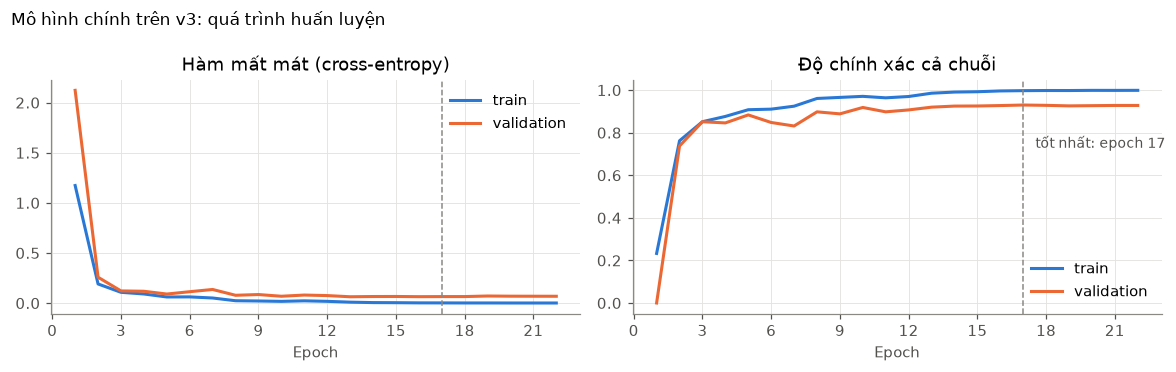

,loss,val_loss,token_acc,val_token_acc,seq_acc,val_seq_acc,learning_rate
epoch,,,,,,,
1,1.173122,2.122700,0.598929,0.415054,0.232850,0.000000,1.00e-03
2,0.191092,0.258220,0.945133,0.931133,0.762150,0.737500,1.00e-03
3,0.107768,0.121726,0.969747,0.967564,0.851700,0.851500,1.00e-03
4,0.091111,0.118232,0.975055,0.967607,0.876400,0.846000,1.00e-03
5,0.061350,0.090526,0.982663,0.976774,0.907950,0.883500,1.00e-03
6,0.062055,0.113867,0.982438,0.969124,0.910650,0.848000,1.00e-03
7,0.051055,0.136098,0.985781,0.962377,0.924550,0.831500,1.00e-03
8,0.023855,0.078135,0.993327,0.980719,0.960800,0.898000,5.00e-04
9,0.021198,0.085492,0.994005,0.978385,0.965800,0.888500,5.00e-04


In [15]:
def plot_history(history, title, path):
    epochs = np.arange(1, len(history["loss"]) + 1)
    best = int(np.argmax(history["val_seq_acc"])) + 1
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    for ax, key, label in [(axes[0], "loss", "Hàm mất mát (cross-entropy)"),
                           (axes[1], "seq_acc", "Độ chính xác cả chuỗi")]:
        ax.plot(epochs, history[key], color=PALETTE[0], linewidth=2, label="train")
        ax.plot(epochs, history["val_" + key], color=PALETTE[1], linewidth=2, label="validation")
        ax.axvline(best, color="#8a8984", linewidth=1, linestyle="--")
        ax.set(xlabel="Epoch", title=label)
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.legend(frameon=False)
    axes[1].annotate(f"tốt nhất: epoch {best}", xy=(best, history["val_seq_acc"][best - 1]),
                     xytext=(8, -28), textcoords="offset points", fontsize=9, color="#52514e")
    fig.suptitle(title, x=0.01, ha="left", fontsize=11)
    plt.tight_layout()
    plt.savefig(path, bbox_inches="tight")
    plt.show()


plot_history(main_history, "Mô hình chính trên v3: quá trình huấn luyện", os.path.join(FIG_DIR, "main_learning_curves.png"))
history_table(main_history).style.format(precision=4).format({"learning_rate": "{:.2e}"})

Bảng trên là log từng epoch của lần huấn luyện (lưu trong `task3_outputs/models/main_v3_seed42_history.json`). Đường train tính trên ảnh đã tăng cường và có dropout nên ở các epoch đầu có thể thấp hơn validation. Về sau độ chính xác cả chuỗi trên train lên gần 100% trong khi validation dừng quanh 93%: với 20.000 ảnh, mô hình bắt đầu học vẹt. Dừng sớm và giảm tốc độ học giữ cho validation không đi xuống; mục 12 và 13 thử hai cách chống học vẹt trực tiếp hơn: sinh thêm dữ liệu và tăng cường dữ liệu mạnh hơn.

Kiểm chứng nhận xét ở mục 3.5: `val_seq_acc` tốt nhất (tính với teacher forcing lúc huấn luyện) phải bằng tỷ lệ đọc đúng trên validation khi chạy greedy search với trọng số tốt nhất.

In [16]:
va = data["v3", "validation"]
val_greedy_acc = metrics.sequence_accuracy(va["labels"], greedy_decode(main_model, va["X"]))
print(f"val_seq_acc tốt nhất lúc huấn luyện (teacher forcing): {max(main_history['val_seq_acc']):.4f}")
print(f"Tỷ lệ đọc đúng trên validation bằng greedy search:     {val_greedy_acc:.4f}")

val_seq_acc tốt nhất lúc huấn luyện (teacher forcing): 0.9300
Tỷ lệ đọc đúng trên validation bằng greedy search:     0.9300


## 5. Đánh giá mô hình chính trên tập test v3 (greedy search)

In [17]:
test = data["v3", "test"]
start = time.time()
pred_greedy, att_test = greedy_decode(main_model, test["X"], return_attention=True)
time_greedy = time.time() - start

main_scores = evaluate(test["labels"], pred_greedy)
print(f"Thời gian đọc {len(test['X'])} ảnh test: {time_greedy:.1f} s")
pd.Series({METRIC_NAMES[k]: v for k, v in main_scores.items()}, name="Mô hình chính, test v3").round(4).to_frame()

Thời gian đọc 2000 ảnh test: 1.9 s


,"Mô hình chính, test v3"
Độ chính xác cả chuỗi,0.9410
CER,0.0118
Độ chính xác độ dài,0.9960
R² (cách B),0.9695
NSE (cách B),0.9692
MAE (cách B),0.0526
RMSE (cách B),0.5036


In [18]:
by_length = report_by_length(test["labels"], pred_greedy)
by_length.to_csv(os.path.join(RESULT_DIR, "main_v3_test_by_length_approachA.csv"))
by_length.style.format({"số ảnh": "{:.0f}", "seq_acc": "{:.4f}", "R2": "{:.4f}", "NSE": "{:.4f}",
                        "MAE": "{:,.0f}", "RMSE": "{:,.0f}"})

,số ảnh,seq_acc,R2,NSE,MAE,RMSE
độ dài,,,,,,
3,308,0.9870,0.9999,0.9999,0,3
4,328,0.9512,0.9747,0.9745,42,452
5,354,0.9379,0.9729,0.9726,476,"4,833"
6,310,0.9258,0.9163,0.9134,"9,197","85,039"
7,343,0.9329,0.9534,0.9526,"68,954","630,695"
8,357,0.9160,0.5017,0.0001,"2,310,552","29,776,120"


**Đọc bảng cách A.** MAE và RMSE có đơn vị là chính giá trị số nên tăng rất nhanh theo độ dài: sai một chữ số ở hàng đầu của dãy 8 chữ số làm lệch hàng chục triệu. R² và NSE không có đơn vị nên so được giữa các độ dài, nhưng lại rất nhạy với lỗi **đọc thiếu hoặc thừa chữ số**: giá trị khi đó lệch khoảng 10 lần, một ảnh như vậy đủ làm tổng bình phương sai số vượt cả độ phân tán của nhóm. Ô dưới tách riêng các ảnh bị đọc sai độ dài để kiểm chứng.

Các ảnh đọc sai độ dài (nhãn → mô hình đọc): [('81679357', '8679357'), ('4307124', '434122'), ('8575266', '857526'), ('136008', '1316008'), ('626208', '62628'), ('61170850', '611708513'), ('43841752', '4384052'), ('51553', '5552')]


,số ảnh đọc sai độ dài,NSE (tất cả ảnh),NSE (bỏ ảnh sai độ dài),R² (bỏ ảnh sai độ dài)
độ dài,,,,
3,0,0.9999,0.9999,0.9999
4,0,0.9745,0.9745,0.9747
5,1,0.9726,0.9796,0.9797
6,2,0.9134,0.9794,0.9794
7,2,0.9526,0.9784,0.9786
8,3,0.0001,0.9792,0.9793


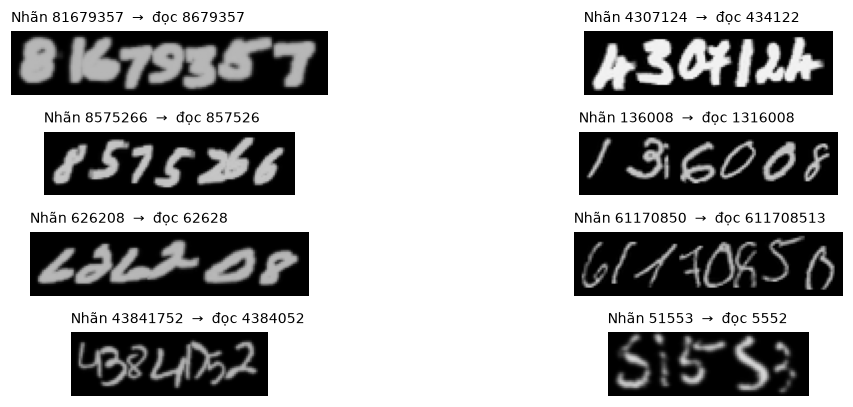

In [19]:
length_errors = [i for i in range(len(test["labels"])) if len(pred_greedy[i]) != len(test["labels"][i])]
print("Các ảnh đọc sai độ dài (nhãn → mô hình đọc):", [(test["labels"][i], pred_greedy[i]) for i in length_errors])

rows = []
for n in range(3, 9):
    group = [i for i in range(len(test["labels"])) if len(test["labels"][i]) == n]
    same_len = [i for i in group if i not in length_errors]
    o_all = [float(test["labels"][i]) for i in group]
    p_all = [float(pred_greedy[i] or 0) for i in group]
    o_ok = [float(test["labels"][i]) for i in same_len]
    p_ok = [float(pred_greedy[i]) for i in same_len]
    rows.append({"độ dài": n, "số ảnh đọc sai độ dài": len(group) - len(same_len),
                 "NSE (tất cả ảnh)": metrics.nse(o_all, p_all), "NSE (bỏ ảnh sai độ dài)": metrics.nse(o_ok, p_ok),
                 "R² (bỏ ảnh sai độ dài)": metrics.r2(o_ok, p_ok)})
display(pd.DataFrame(rows).set_index("độ dài").round(4))

fig, axes = plt.subplots(int(np.ceil(len(length_errors) / 2)), 2, figsize=(11, 0.95 * np.ceil(len(length_errors) / 2)))
for ax in np.atleast_1d(axes).ravel():
    ax.axis("off")
for ax, i in zip(np.atleast_1d(axes).ravel(), length_errors):
    w = int(np.flatnonzero(test["X"][i].max(axis=0) > 0).max()) + 5      # bỏ phần nền đen đệm bên phải
    ax.imshow(test["X"][i][:, :w], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Nhãn {test['labels'][i]}  →  đọc {pred_greedy[i]}", fontsize=9, loc="left")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "length_error_examples.png"), bbox_inches="tight")
plt.show()

Ở nhóm 8 chữ số, chỉ 3 ảnh đọc sai độ dài đã kéo NSE của cả nhóm xuống gần 0; bỏ 8 ảnh sai độ dài thì NSE và R² theo cách A đều trên 0,97 ở mọi độ dài. Nhìn ảnh có thể thấy hai nguyên nhân: hai chữ số chạm nhau bị đọc thành một, hay gặp nhất là chữ số 1 mảnh dính vào chữ số bên cạnh (ví dụ `81679357` → `8679357`); hoặc một nét thừa, một chữ số viết hở bị đọc thành thêm một chữ số (ví dụ chữ số 0 cuối của `61170850` bị đọc thành `13`). Nhiều ảnh mơ hồ ngay cả với người đọc. Vì vậy cách B (gom mọi chữ số về cùng thang 0–9) ổn định hơn và phù hợp hơn để so sánh các mô hình, còn cách A cho thấy hậu quả thực tế khi đọc sai một con số.

## 6. Thí nghiệm E7: greedy search và beam search

Câu hỏi: beam search (k = 3, k = 5) có đọc đúng hơn greedy không, và có đáng thời gian chạy thêm không?

In [20]:
decode_rows, pred_beam = [], {}
for k in [1, 3, 5]:
    start = time.time()
    pred = pred_greedy if k == 1 else beam_search(main_model, test["X"], beam_size=k)
    elapsed = time_greedy if k == 1 else time.time() - start
    pred_beam[k] = pred
    scores = evaluate(test["labels"], pred)
    decode_rows.append({"cách đọc": "greedy" if k == 1 else f"beam k = {k}",
                        "số ảnh khác greedy": sum(p != g for p, g in zip(pred, pred_greedy)),
                        **{METRIC_NAMES[m]: scores[m] for m in ["seq_acc", "CER", "len_acc", "R2_B", "NSE_B"]},
                        "thời gian (s)": elapsed})
decode_table = pd.DataFrame(decode_rows).set_index("cách đọc")
decode_table.to_csv(os.path.join(RESULT_DIR, "E7_greedy_vs_beam.csv"))
decode_table.round(4)

,số ảnh khác greedy,Độ chính xác cả chuỗi,CER,Độ chính xác độ dài,R² (cách B),NSE (cách B),thời gian (s)
cách đọc,,,,,,,
greedy,0,0.9410,0.0118,0.996,0.9695,0.9692,1.8836
beam k = 3,4,0.9425,0.0114,0.996,0.9719,0.9717,2.2793
beam k = 5,4,0.9425,0.0114,0.996,0.9719,0.9717,2.4071


## 7. Trực quan hoá attention

Với mỗi chữ số đọc ra, hàng tương ứng của bản đồ cho biết trọng số $\alpha$ trên 64 cột (mỗi cột rộng 4 pixel, đã căn thẳng với ảnh phía trên). Nếu mô hình học đúng, vùng đậm phải trượt dần từ trái sang phải theo từng chữ số, và bước `<eos>` nhìn vào khoảng trống sau chữ số cuối.

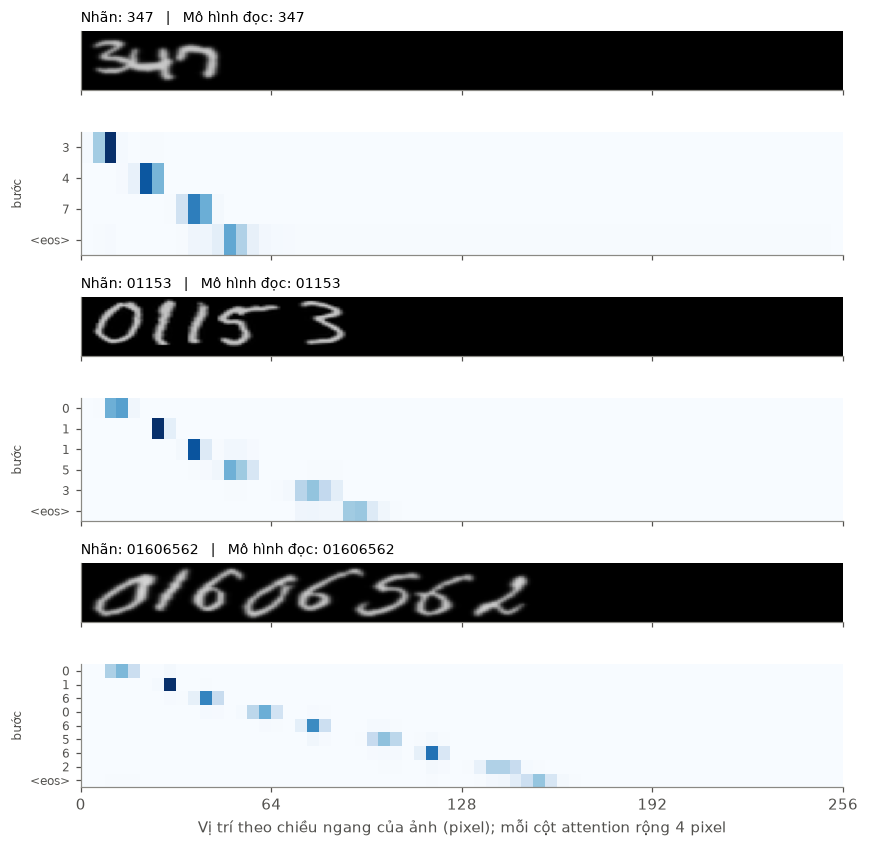

In [21]:
def plot_attention(indices, path):
    # Mỗi ví dụ: ảnh ở trên, bản đồ attention ở dưới, dùng chung trục ngang 0-256 pixel
    fig, axes = plt.subplots(2 * len(indices), 1, figsize=(8, 2.6 * len(indices)), sharex=True,
                             gridspec_kw={"height_ratios": [1, 2.1] * len(indices)})
    for j, i in enumerate(indices):
        pred = pred_greedy[i]
        n_steps = len(pred) + 1                                  # các chữ số + <eos>
        ax_img, ax_att = axes[2 * j], axes[2 * j + 1]
        ax_img.imshow(test["X"][i], cmap="gray", vmin=0, vmax=255, aspect="auto", extent=[0, IMG_W, IMG_H, 0])
        ax_img.set_title(f"Nhãn: {test['labels'][i]}   |   Mô hình đọc: {pred}", fontsize=9, loc="left")
        ax_img.set_yticks([])
        ax_img.grid(False)
        ax_att.imshow(att_test[i, :n_steps], cmap="Blues", aspect="auto", vmin=0,
                      extent=[0, IMG_W, n_steps, 0], interpolation="nearest")
        ax_att.set_yticks(np.arange(n_steps) + 0.5, list(pred) + ["<eos>"], fontsize=8)
        ax_att.set_ylabel("bước", fontsize=8)
        ax_att.grid(False)
    axes[-1].set_xticks([0, 64, 128, 192, 256])
    axes[-1].set_xlabel("Vị trí theo chiều ngang của ảnh (pixel); mỗi cột attention rộng 4 pixel")
    plt.tight_layout()
    plt.savefig(path, bbox_inches="tight")
    plt.show()


lengths_test = np.array([len(t) for t in test["labels"]])
correct_test = np.array([t == p for t, p in zip(test["labels"], pred_greedy)])
examples = []
for n in (3, 5, 8):                                   # mỗi độ dài lấy ảnh đọc đúng đầu tiên
    candidates = np.flatnonzero((lengths_test == n) & correct_test)
    if len(candidates) == 0:
        candidates = np.flatnonzero(lengths_test == n)
    examples.append(int(candidates[0]))
plot_attention(examples, os.path.join(FIG_DIR, "attention_examples.png"))

In [22]:
# Kiểm tra định lượng: tâm attention của các bước chữ số có tăng dần từ trái sang phải không?
cols = np.arange(N_COLS)
monotonic = []
for i in np.flatnonzero(correct_test):
    n = lengths_test[i]
    centers = (att_test[i, :n] * cols).sum(-1)              # tâm trọng số (theo cột) của từng chữ số
    monotonic.append(np.all(np.diff(centers) > 0))
if monotonic:
    print(f"Ảnh đọc đúng có tâm attention tăng dần từ trái sang phải: "
          f"{np.mean(monotonic):.2%} ({np.sum(monotonic)}/{len(monotonic)})")

Ảnh đọc đúng có tâm attention tăng dần từ trái sang phải: 100.00% (1882/1882)


## 8. Phân tích lỗi

In [23]:
errors = np.flatnonzero(~correct_test)
pred_lengths = np.array([len(p) for p in pred_greedy])
error_types = pd.Series({
    "đọc đúng hoàn toàn": int(correct_test.sum()),
    "sai, đúng độ dài (thay chữ số)": int(((pred_lengths == lengths_test) & ~correct_test).sum()),
    "đọc thiếu chữ số": int((pred_lengths < lengths_test).sum()),
    "đọc thừa chữ số": int((pred_lengths > lengths_test).sum()),
}, name="số ảnh test")
print(error_types.to_string())

# Các cặp nhầm lẫn thường gặp (chỉ xét ảnh đọc đúng độ dài)
swaps = pd.Series([f"{a} → {b}" for i in errors if pred_lengths[i] == lengths_test[i]
                   for a, b in zip(test["labels"][i], pred_greedy[i]) if a != b])
print("\nCặp nhầm lẫn thường gặp (thật → đọc):")
print(swaps.value_counts().head(8).to_string())

đọc đúng hoàn toàn                1882
sai, đúng độ dài (thay chữ số)     110
đọc thiếu chữ số                     6
đọc thừa chữ số                      2

Cặp nhầm lẫn thường gặp (thật → đọc):
8 → 9    10
4 → 9     9
8 → 2     8
5 → 3     7
9 → 7     7
9 → 4     7
2 → 7     6
5 → 6     5


**Theo nhóm người viết.** File nhãn của v3 có mã người viết của từng ảnh, nên có thể xem mô hình đọc chữ của nhóm nào khó hơn. NIST thu chữ của hai nhóm: nhân viên Cục Điều tra Dân số Mỹ (mã nhỏ hơn 2100) và học sinh trung học (mã từ 2100 trở lên). Ở tập test, chuỗi dài lấy từ nhân viên nhiều hơn (xem mục 9 của notebook 04), nên bảng dưới tách cả theo độ dài.

In [24]:
test_writer = pd.read_csv(os.path.join(V3_DIR, "test_labels.csv"), dtype={"label": str, "source": str},
                          encoding="utf-8-sig")["writer"].to_numpy()[:len(test["labels"])]
writer_group = np.where(test_writer >= 2100, "học sinh", "nhân viên")
by_group = pd.DataFrame({"nhóm người viết": writer_group, "độ dài": lengths_test, "đọc đúng": correct_test})
group_table = by_group.groupby("nhóm người viết")["đọc đúng"].agg(["size", "mean"])
group_table.columns = ["số ảnh", "độ chính xác cả chuỗi"]
group_table["số người viết"] = pd.Series(test_writer).groupby(writer_group).nunique()
display(group_table.round(4))
by_group.pivot_table(index="nhóm người viết", columns="độ dài", values="đọc đúng", aggfunc="mean").round(3)

,số ảnh,độ chính xác cả chuỗi,số người viết
nhóm người viết,,,
học sinh,1295,0.9328,228
nhân viên,705,0.9560,48


độ dài,3,4,5,6,7,8
nhóm người viết,,,,,,
học sinh,0.988,0.944,0.940,0.916,0.898,0.889
nhân viên,0.983,0.968,0.933,0.941,0.979,0.946


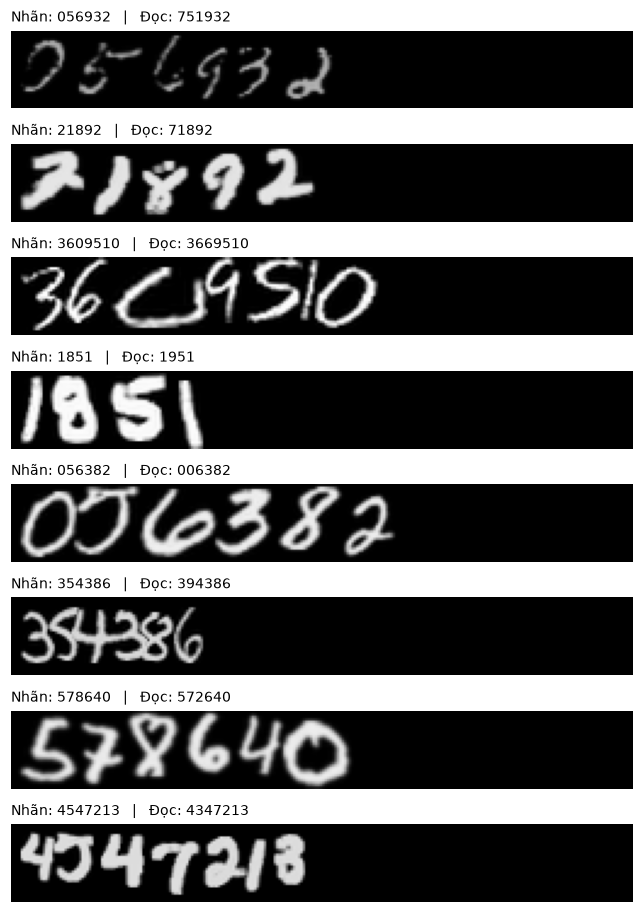

In [25]:
show = errors[:8]                                     # 8 ảnh đọc sai đầu tiên của tập test
if len(show) > 0:
    fig, axes = plt.subplots(len(show), 1, figsize=(7, 1.05 * len(show)))
    for ax, i in zip(np.atleast_1d(axes), show):
        ax.imshow(test["X"][i], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"Nhãn: {test['labels'][i]}   |   Đọc: {pred_greedy[i]}", fontsize=9, loc="left")
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "error_examples.png"), bbox_inches="tight")
    plt.show()

In [26]:
pd.DataFrame({"image_path": [f"test/{i:06d}.png" for i in range(len(test["labels"]))],
              "label": test["labels"], "pred_greedy": pred_greedy, "pred_beam3": pred_beam[3],
              "correct_greedy": correct_test}).to_csv(os.path.join(RESULT_DIR, "main_v3_test_predictions.csv"), index=False)

**Ma trận nhầm lẫn.** Với các ảnh đọc đúng số lượng chữ số, so từng vị trí: hàng là chữ số thật, cột là chữ số mô hình đọc. Hình chỉ vẽ các ô ngoài đường chéo, tức các lần đọc nhầm.

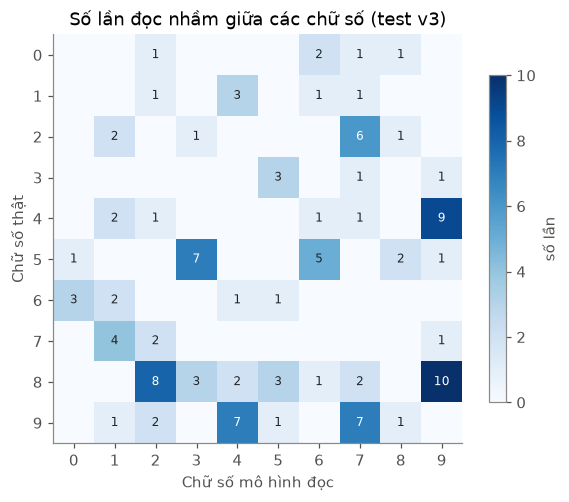

chữ số,0,1,2,3,4,5,6,7,8,9
số lần xuất hiện,1155.0000,1056.0000,1162.0000,1052.0000,1073.000,1160.0000,1086.0000,1144.0000,1125.0000,1055.000
số lần đọc đúng,1150.0000,1050.0000,1152.0000,1047.0000,1059.000,1144.0000,1079.0000,1137.0000,1096.0000,1036.000
tỷ lệ đọc đúng,0.9957,0.9943,0.9914,0.9952,0.987,0.9862,0.9936,0.9939,0.9742,0.982


In [27]:
conf_mat = np.zeros((10, 10), dtype=int)
for t, p in zip(test["labels"], pred_greedy):
    if len(t) == len(p):
        for a, b in zip(t, p):
            conf_mat[int(a), int(b)] += 1
errors_only = conf_mat.copy()
np.fill_diagonal(errors_only, 0)

fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(errors_only, cmap="Blues", vmin=0)
for a in range(10):
    for b in range(10):
        if errors_only[a, b] > 0:
            ax.text(b, a, errors_only[a, b], ha="center", va="center", fontsize=8,
                    color="white" if errors_only[a, b] > errors_only.max() / 2 else "#202124")
ax.set(xticks=range(10), yticks=range(10), xlabel="Chữ số mô hình đọc", ylabel="Chữ số thật",
       title="Số lần đọc nhầm giữa các chữ số (test v3)")
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.8, label="số lần")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "digit_confusion_matrix.png"), bbox_inches="tight")
plt.show()

per_digit = pd.DataFrame({"số lần xuất hiện": conf_mat.sum(axis=1), "số lần đọc đúng": np.diag(conf_mat)}, index=range(10))
per_digit["tỷ lệ đọc đúng"] = per_digit["số lần đọc đúng"] / per_digit["số lần xuất hiện"]
per_digit.index.name = "chữ số"
per_digit.T.round(4)

### Đọc kèm độ tự tin: khi nào nên để người kiểm tra lại?

Khi dùng thật (đọc số tiền, chỉ số công tơ), thà để người kiểm tra lại vài ảnh còn hơn đọc sai. Ở mỗi bước, softmax cho biết token được chọn có xác suất bao nhiêu. Nhóm lấy **độ tự tin của một ảnh = xác suất nhỏ nhất trong các bước từ đầu tới `<eos>`**: chỉ cần một chữ số không chắc là cả chuỗi không chắc.

Hàm `decode_with_confidence` chạy greedy search như mục 3.6 và trả về thêm độ tự tin. Hàm nhận một danh sách mô hình: với nhiều mô hình, ở mỗi bước nó lấy trung bình xác suất của các mô hình (dùng ở mục 10); với một mô hình, kết quả đọc trùng hệt `greedy_decode`.

Bảng dưới sắp các ảnh test theo độ tự tin giảm dần, cho mô hình tự đọc phần tự tin nhất và chuyển phần còn lại cho người kiểm tra.

Kết quả đọc trùng greedy_decode: True


,số ảnh chuyển cho người kiểm tra,độ chính xác trên ảnh tự đọc,số ảnh sai vẫn lọt qua,ngưỡng độ tự tin
tỷ lệ ảnh mô hình tự đọc,,,,
1.000000,0,0.9410,118,0.3759
0.990000,20,0.9485,102,0.5701
0.980000,40,0.9531,92,0.6764
0.950000,100,0.9684,60,0.9081
0.900000,200,0.9806,35,0.9872
0.800000,400,0.9925,12,0.9990


Ảnh đọc sai mà mọi bước vẫn có xác suất trên 0,9: 55% (65/118); ảnh đọc đúng: 97.9%


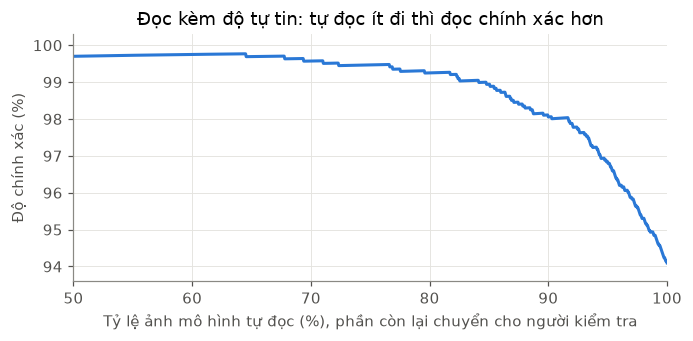

In [28]:
def decode_with_confidence(models, X, batch_size=250):
    preds, confidence = [], []
    for i in range(0, len(X), batch_size):
        x = to_float(X[i:i + batch_size])
        with inference_mode():
            runs = [list(m.init_decoder(x)) for m in models]          # [H, W h_i, c cố định, trạng thái] của từng mô hình
            y = ops.full((len(x),), BOS, dtype="int32")
            tokens, pmax = [], []
            for _ in range(T_DEC):
                probs = 0
                for run, m in zip(runs, models):
                    p, run[3], _ = m.step(y, run[3], run[0], run[1], run[2])
                    probs = probs + p / len(models)                 # trung bình xác suất của các mô hình
                y = ops.cast(ops.argmax(probs, axis=-1), "int32")
                tokens.append(ops.convert_to_numpy(y))
                pmax.append(ops.convert_to_numpy(ops.max(probs, axis=-1)))
        tokens, pmax = np.stack(tokens, 1), np.stack(pmax, 1)
        for t, pm in zip(tokens, pmax):
            n = int(np.argmax(t == EOS)) + 1 if (t == EOS).any() else T_DEC   # các bước tới <eos>
            preds.append(decode_tokens(t))
            confidence.append(float(pm[:n].min()))
    return preds, np.array(confidence)


pred_conf, conf_main = decode_with_confidence([main_model], test["X"])
print("Kết quả đọc trùng greedy_decode:", pred_conf == pred_greedy)
order = np.argsort(-conf_main, kind="stable")                         # tự tin nhất trước
ok_sorted = correct_test[order]
coverage_rows = []
for keep in [1.0, 0.99, 0.98, 0.95, 0.90, 0.80]:
    k = int(round(keep * len(order)))
    coverage_rows.append({"tỷ lệ ảnh mô hình tự đọc": keep, "số ảnh chuyển cho người kiểm tra": len(order) - k,
                          "độ chính xác trên ảnh tự đọc": ok_sorted[:k].mean(),
                          "số ảnh sai vẫn lọt qua": int((~ok_sorted[:k]).sum()),
                          "ngưỡng độ tự tin": conf_main[order[k - 1]]})
coverage_table = pd.DataFrame(coverage_rows).set_index("tỷ lệ ảnh mô hình tự đọc")
coverage_table.to_csv(os.path.join(RESULT_DIR, "main_v3_confidence_coverage.csv"))
display(coverage_table.style.format({"độ chính xác trên ảnh tự đọc": "{:.4f}", "ngưỡng độ tự tin": "{:.4f}"}))
print(f"Ảnh đọc sai mà mọi bước vẫn có xác suất trên 0,9: {np.mean(conf_main[~correct_test] > 0.9):.0%} "
      f"({np.sum(conf_main[~correct_test] > 0.9)}/{np.sum(~correct_test)}); "
      f"ảnh đọc đúng: {np.mean(conf_main[correct_test] > 0.9):.1%}")

cover = np.arange(1, len(order) + 1) / len(order)
acc_curve = np.cumsum(ok_sorted) / np.arange(1, len(order) + 1)
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(cover * 100, acc_curve * 100, color=PALETTE[0], linewidth=2)
ax.set(xlim=(50, 100), ylim=(acc_curve[len(order) // 2:].min() * 100 - 0.5, 100.3),
       xlabel="Tỷ lệ ảnh mô hình tự đọc (%), phần còn lại chuyển cho người kiểm tra",
       ylabel="Độ chính xác (%)", title="Đọc kèm độ tự tin: tự đọc ít đi thì đọc chính xác hơn")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "confidence_coverage.png"), bbox_inches="tight")
plt.show()

**Nhận xét.**
- Chuyển 5% ảnh kém tự tin nhất (100 ảnh) cho người kiểm tra thì số ảnh sai lọt qua giảm gần một nửa (118 → 60), độ chính xác trên phần mô hình tự đọc lên 96,8%. Chuyển 10% thì còn 35 ảnh sai (98,1%); chuyển 20% thì còn 12 ảnh sai (99,3%).
- Không bao giờ lọc hết được lỗi: hơn một nửa số ảnh đọc sai có mọi bước với xác suất trên 0,9 (dòng in dưới bảng), tức mô hình sai một cách tự tin. Ngay cả khi chỉ tự đọc 50% ảnh tự tin nhất, độ chính xác vẫn chưa đạt 100%.
- Khi dùng thật (đọc số tiền, chỉ số công tơ), có thể chọn ngưỡng độ tự tin theo số ảnh mà người kiểm tra xử lý được: bảng trên cho biết mỗi ngưỡng đổi được bao nhiêu lỗi.

## 9. Thí nghiệm E6: so sánh kiến trúc

Bốn mô hình dùng chung CNN encoder, cùng dữ liệu, siêu tham số và seed; mỗi mô hình sau bỏ đi đúng một thành phần so với mô hình chính, để thấy thành phần đó đóng góp bao nhiêu:

| Mô hình | Mô tả |
|---|---|
| CNN + nhiều đầu softmax | Mốc không có RNN: 9 đầu softmax đoán 9 vị trí cùng lúc (mục 3.4) |
| CNN + BiLSTM + LSTM decoder | Bỏ attention: decoder chỉ nhận vector $c$ cố định của chương 8 |
| CNN + LSTM decoder + Attention | Bỏ BiLSTM: attention nhìn thẳng vào các cột của CNN |
| CNN + BiLSTM + LSTM decoder + Attention | Mô hình chính |

In [29]:
MODELS = {
    "CNN + nhiều đầu softmax": ("multihead_v3_seed42", build_multihead),
    "CNN + BiLSTM + LSTM decoder": ("noatt_v3_seed42", lambda: Img2Seq(use_bilstm=True, use_attention=False)),
    "CNN + LSTM decoder + Attention": ("nobilstm_v3_seed42", lambda: Img2Seq(use_bilstm=False, use_attention=True)),
}
trained = {"CNN + BiLSTM + LSTM decoder + Attention": (main_model, main_history)}
if RUN_EXPERIMENTS:
    for label, (name, make) in MODELS.items():
        print(f"\n===== {label} =====")
        trained[label] = train_or_load(name, make)


===== CNN + nhiều đầu softmax =====


Đọc trọng số đã huấn luyện: task3_outputs/models/multihead_v3_seed42.weights.h5
  (lần huấn luyện trước: 30 epoch, 23.1 phút; tốt nhất ở epoch 29 với val_seq_acc = 0.7605)

===== CNN + BiLSTM + LSTM decoder =====


Đọc trọng số đã huấn luyện: task3_outputs/models/noatt_v3_seed42.weights.h5
  (lần huấn luyện trước: 30 epoch, 30.2 phút; tốt nhất ở epoch 28 với val_seq_acc = 0.9260)

===== CNN + LSTM decoder + Attention =====


Đọc trọng số đã huấn luyện: task3_outputs/models/nobilstm_v3_seed42.weights.h5
  (lần huấn luyện trước: 30 epoch, 25.7 phút; tốt nhất ở epoch 26 với val_seq_acc = 0.7795)


In [30]:
order = ["CNN + nhiều đầu softmax", "CNN + BiLSTM + LSTM decoder", "CNN + LSTM decoder + Attention",
         "CNN + BiLSTM + LSTM decoder + Attention"]
order = [m for m in order if m in trained]
compare_rows, preds_by_model = [], {}
for label in order:
    model, history = trained[label]
    pred = pred_greedy if model is main_model else greedy_decode(model, test["X"])
    preds_by_model[label] = pred
    row = describe(label, model, history)
    row.update({METRIC_NAMES[k]: v for k, v in evaluate(test["labels"], pred).items()})
    compare_rows.append(row)
compare_table = pd.DataFrame(compare_rows).set_index("mô hình")
compare_table.to_csv(os.path.join(RESULT_DIR, "E6_architecture_comparison.csv"))
compare_table.style.format(precision=4).format(
    {"số tham số": "{:,.0f}", "số epoch": "{:.0f}", "epoch tốt nhất": "{:.0f}", "thời gian huấn luyện (phút)": "{:.1f}"})

,số tham số,số epoch,epoch tốt nhất,val_seq_acc tốt nhất,thời gian huấn luyện (phút),Độ chính xác cả chuỗi,CER,Độ chính xác độ dài,R² (cách B),NSE (cách B),MAE (cách B),RMSE (cách B)
mô hình,,,,,,,,,,,,
CNN + nhiều đầu softmax,"9,709,429",30,29,0.760500,23.1,0.767500,0.060505,0.978000,0.836775,0.829305,0.279569,1.186854
CNN + BiLSTM + LSTM decoder,"2,252,877",30,28,0.926000,30.2,0.933000,0.015913,0.994500,0.960298,0.959890,0.068656,0.575063
CNN + LSTM decoder + Attention,"2,056,013",30,26,0.779500,25.7,0.795000,0.080284,0.989000,0.783433,0.770209,0.380311,1.376882
CNN + BiLSTM + LSTM decoder + Attention,"2,318,669",22,17,0.930000,23.4,0.941000,0.011777,0.996000,0.969470,0.969233,0.052584,0.503560


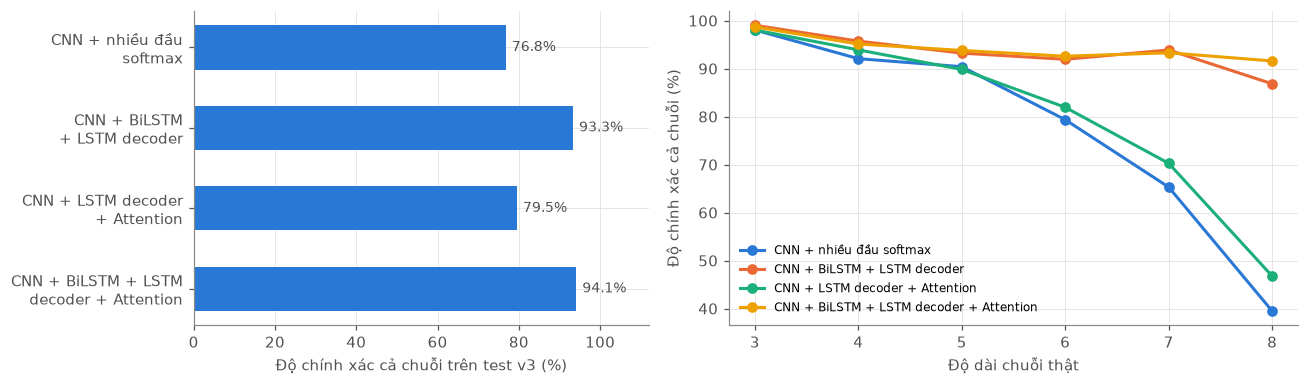

độ dài,3,4,5,6,7,8
CNN + nhiều đầu softmax,0.9805,0.9207,0.9040,0.7935,0.6531,0.3950
CNN + BiLSTM + LSTM decoder,0.9903,0.9573,0.9322,0.9194,0.9388,0.8683
CNN + LSTM decoder + Attention,0.9805,0.9390,0.8983,0.8194,0.7026,0.4678
CNN + BiLSTM + LSTM decoder + Attention,0.9870,0.9512,0.9379,0.9258,0.9329,0.9160


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.25]})
acc = compare_table["Độ chính xác cả chuỗi"]
short = ["CNN + nhiều đầu\nsoftmax", "CNN + BiLSTM\n+ LSTM decoder", "CNN + LSTM decoder\n+ Attention",
         "CNN + BiLSTM + LSTM\ndecoder + Attention"]
short = [s for s, m in zip(short, ["CNN + nhiều đầu softmax", "CNN + BiLSTM + LSTM decoder",
                                   "CNN + LSTM decoder + Attention", "CNN + BiLSTM + LSTM decoder + Attention"]) if m in order]
bars = axes[0].barh(np.arange(len(order)), acc.values * 100, color=PALETTE[0], height=0.55)
axes[0].bar_label(bars, labels=[f"{v:.1%}" for v in acc.values], padding=4, fontsize=9, color="#52514e")
axes[0].set(yticks=np.arange(len(order)), yticklabels=short, xlim=(0, 112), xlabel="Độ chính xác cả chuỗi trên test v3 (%)")
axes[0].invert_yaxis()

for j, label in enumerate(order):
    ok = np.array([t == p for t, p in zip(test["labels"], preds_by_model[label])])
    per_len = [ok[lengths_test == n].mean() * 100 for n in range(3, 9)]
    axes[1].plot(range(3, 9), per_len, marker="o", markersize=6, linewidth=2, color=PALETTE[j], label=short[j].replace("\n", " "))
axes[1].set(xlabel="Độ dài chuỗi thật", ylabel="Độ chính xác cả chuỗi (%)", xticks=range(3, 9))
axes[1].legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "E6_architecture_comparison.png"), bbox_inches="tight")
plt.show()

per_length = pd.DataFrame({label: [np.mean([t == p for t, p in zip(test["labels"], preds_by_model[label]) if len(t) == n])
                                   for n in range(3, 9)] for label in order}, index=range(3, 9)).T
per_length.columns.name = "độ dài"
per_length.to_csv(os.path.join(RESULT_DIR, "E6_accuracy_by_length.csv"))
per_length.round(4)

## 10. Độ ổn định của mô hình chính qua 3 seed

Kết quả một lần huấn luyện phụ thuộc vào khởi tạo trọng số và thứ tự batch. Nhóm huấn luyện lại mô hình chính với seed 43 và 44 rồi báo cáo trung bình ± độ lệch chuẩn, để chênh lệch nhỏ giữa các mô hình không bị hiểu nhầm là cải tiến.

In [32]:
seed_rows = [{"seed": SEED, **evaluate(test["labels"], pred_greedy)}]
seed_models, seed_preds = {SEED: main_model}, {SEED: pred_greedy}
if RUN_EXPERIMENTS:
    for seed in [43, 44]:
        print(f"\n===== Mô hình chính, seed {seed} =====")
        model_s, history_s = train_or_load(f"main_v3_seed{seed}", lambda: Img2Seq(True, True), seed=seed)
        seed_models[seed], seed_preds[seed] = model_s, greedy_decode(model_s, test["X"])
        seed_rows.append({"seed": seed, **evaluate(test["labels"], seed_preds[seed])})
seed_table = pd.DataFrame(seed_rows).set_index("seed").rename(columns=METRIC_NAMES)
seed_table.loc["trung bình"] = seed_table.iloc[:3].mean()
seed_table.loc["độ lệch chuẩn"] = seed_table.iloc[:3].std(ddof=1)
seed_table.to_csv(os.path.join(RESULT_DIR, "main_v3_three_seeds.csv"))
seed_table.round(4)


===== Mô hình chính, seed 43 =====
Đọc trọng số đã huấn luyện: task3_outputs/models/main_v3_seed43.weights.h5
  (lần huấn luyện trước: 25 epoch, 26.9 phút; tốt nhất ở epoch 20 với val_seq_acc = 0.9340)



===== Mô hình chính, seed 44 =====
Đọc trọng số đã huấn luyện: task3_outputs/models/main_v3_seed44.weights.h5
  (lần huấn luyện trước: 19 epoch, 20.5 phút; tốt nhất ở epoch 14 với val_seq_acc = 0.9320)


,Độ chính xác cả chuỗi,CER,Độ chính xác độ dài,R² (cách B),NSE (cách B),MAE (cách B),RMSE (cách B)
seed,,,,,,,
42,0.9410,0.0118,0.9960,0.9695,0.9692,0.0526,0.5036
43,0.9450,0.0105,0.9955,0.9725,0.9724,0.0465,0.4774
44,0.9445,0.0109,0.9960,0.9723,0.9721,0.0482,0.4800
trung bình,0.9435,0.0111,0.9958,0.9714,0.9712,0.0491,0.4870
độ lệch chuẩn,0.0022,0.0006,0.0003,0.0017,0.0017,0.0031,0.0144


### Gộp 3 mô hình (ensemble)

Ba mô hình chỉ khác nhau ở seed nên thường không sai ở cùng những ảnh. Có thể cho cả ba cùng đọc: ở mỗi bước của greedy search, lấy trung bình xác suất của ba mô hình, chọn token có xác suất trung bình cao nhất, rồi đưa token đó vào cả ba decoder ở bước sau. Hàm `decode_with_confidence` ở mục 8 làm đúng việc này. Cái giá là thời gian đọc gấp khoảng ba lần.

In [33]:
if RUN_EXPERIMENTS:
    start = time.time()
    pred_ens, conf_ens = decode_with_confidence(list(seed_models.values()), test["X"])
    time_ens = time.time() - start
    ens_rows = [{"cách đọc": f"seed {s}", **{METRIC_NAMES[k]: v for k, v in evaluate(test["labels"], p).items()}}
                for s, p in seed_preds.items()]
    ens_rows.append({"cách đọc": "gộp 3 seed (ensemble)",
                     **{METRIC_NAMES[k]: v for k, v in evaluate(test["labels"], pred_ens).items()}})
    ens_table = pd.DataFrame(ens_rows).set_index("cách đọc")
    ens_table.to_csv(os.path.join(RESULT_DIR, "main_v3_ensemble.csv"))
    display(ens_table.round(4))
    print(f"Thời gian đọc {len(test['X'])} ảnh: gộp 3 mô hình {time_ens:.1f} s, một mô hình {time_greedy:.1f} s")

,Độ chính xác cả chuỗi,CER,Độ chính xác độ dài,R² (cách B),NSE (cách B),MAE (cách B),RMSE (cách B)
cách đọc,,,,,,,
seed 42,0.9410,0.0118,0.9960,0.9695,0.9692,0.0526,0.5036
seed 43,0.9450,0.0105,0.9955,0.9725,0.9724,0.0465,0.4774
seed 44,0.9445,0.0109,0.9960,0.9723,0.9721,0.0482,0.4800
gộp 3 seed (ensemble),0.9535,0.0089,0.9960,0.9754,0.9752,0.0416,0.4522


Thời gian đọc 2000 ảnh: gộp 3 mô hình 5.5 s, một mô hình 1.9 s


## 11. Ghép chuỗi từ nhiều người viết (v2) hay một người viết (v3)?

Trước khi sửa dữ liệu theo góp ý của giảng viên, nhóm đã huấn luyện mô hình chính trên v2, nơi mỗi chữ số của chuỗi lấy từ một ảnh MNIST bất kỳ (trung bình 5,5 người viết mỗi ảnh). Mục này đánh giá chéo mô hình đó (trọng số `main_v2_seed42` của lần huấn luyện trước: cùng kiến trúc, siêu tham số và seed, 20.000 ảnh train) với mô hình chính học trên v3, trên cả hai tập test. Hai tập test đều ghép từ chữ số của MNIST-test, chỉ khác cách ghép.

In [34]:
cross_rows, cross_preds = [], {}
if RUN_EXPERIMENTS and ("v2", "test") in data:
    model_v2, history_v2 = train_or_load("main_v2_seed42", lambda: Img2Seq(True, True), version="v2")
    for train_name, model in [("train v2", model_v2), ("train v3", main_model)]:
        for test_version in ["v2", "v3"]:
            t = data[test_version, "test"]
            pred = pred_greedy if (model is main_model and test_version == "v3") else greedy_decode(model, t["X"])
            cross_preds[train_name, test_version] = pred
            s = evaluate(t["labels"], pred)
            cross_rows.append({"mô hình": train_name, "tập test": test_version,
                               **{METRIC_NAMES[k]: s[k] for k in ["seq_acc", "CER", "len_acc", "R2_B", "NSE_B"]}})
    cross_table = pd.DataFrame(cross_rows).set_index(["mô hình", "tập test"])
    cross_table.to_csv(os.path.join(RESULT_DIR, "v2_vs_v3_cross_test.csv"))
    display(cross_table.round(4))

Đọc trọng số đã huấn luyện: task3_outputs/models/main_v2_seed42.weights.h5
  (lần huấn luyện trước: 21 epoch, 24.3 phút; tốt nhất ở epoch 16 với val_seq_acc = 0.9315)


Độ chính xác cả chuỗi     CER  Độ chính xác độ dài  \
mô hình  tập test                                                       
train v2 v2                       0.9355  0.0120               0.9960   
         v3                       0.9370  0.0127               0.9875   
train v3 v2                       0.9160  0.0166               0.9820   
         v3                       0.9410  0.0118               0.9960   

                   R² (cách B)  NSE (cách B)  
mô hình  tập test                             
train v2 v2             0.9697        0.9695  
         v3             0.9554        0.9549  
train v3 v2             0.9423        0.9413  
         v3             0.9695        0.9692

**Nhận xét.**
- Hai tập test khó tương đương nhau: mô hình học trên v2 đạt 93,55% trên test v2 và 93,70% trên test v3. Vì vậy không so thẳng 93,55% (v2) với 94,10% (v3) như một mức cải thiện.
- Trên test v3, nơi mỗi chuỗi do một người viết như ngoài đời, mô hình học trên v3 đọc đúng cả chuỗi hơn 0,40 điểm và nhất là đếm đúng số chữ số hơn: chỉ 8 ảnh sai độ dài, so với 25 ảnh của mô hình học trên v2. Mục 14 kiểm tra hai chênh lệch này bằng bootstrap.
- Trên test v2, mô hình học trên v3 kém hơn (91,60%) vì chưa từng thấy chuỗi trộn nhiều kiểu chữ; loại chuỗi này không có ngoài đời.
- Vì vậy nhóm dùng v3: đúng bản chất của chuỗi số viết tay, và trên đúng loại chuỗi đó mô hình học trên v3 đếm số chữ số tốt hơn.

## 12. Thêm dữ liệu tổng hợp: 20.000 hay 60.000 ảnh train?

Đường học ở mục 4 cho thấy độ chính xác cả chuỗi trên tập train cao hơn hẳn validation: với 20.000 ảnh, mô hình bắt đầu học vẹt. Cách tự nhiên nhất theo chương 5.3 là **sinh thêm dữ liệu** (proposal cũng dự kiến 60.000 ảnh train). Script `generate_data_v3.py` dùng seed cố định cho từng tập và cùng một cách chia người viết, nên khi sinh bộ lớn (`--train 60000`), 20.000 ảnh train đầu tiên, toàn bộ validation và test trùng với v3; chỉ có thêm 40.000 ảnh train mới, vẫn chỉ dùng chữ của 431 người viết dành cho train nên không rò rỉ sang validation và test. (Nếu sinh lại bằng phiên bản thư viện Pillow khác, một số ảnh có thể lệch vài mức xám, nhưng nhãn và người viết vẫn trùng.) Để so sánh công bằng, mô hình chính được huấn luyện lại trên 60.000 ảnh với đúng các siêu tham số cũ, chọn epoch trên tập validation v3 và đánh giá trên tập test v3.

In [35]:
import subprocess

V3BIG_DIR = os.path.join(TASK3_DATA, "mnist_sequences_v3_big")
if RUN_EXPERIMENTS:
    if not os.path.exists(V3BIG_DIR):          # sinh bộ lớn, khoảng 1 phút
        subprocess.run([sys.executable, "generate_data_v3.py", "--out", "data/mnist_sequences_v3_big",
                        "--train", "60000"], cwd=os.path.join(DATA_ROOT, "task3"), check=True)
    data["v3big", "train"] = load_split(V3BIG_DIR, "train")
    data["v3big", "validation"] = data["v3", "validation"]      # chọn epoch trên đúng tập validation v3
    print("Số ảnh train của bộ lớn:", len(data["v3big", "train"]["X"]))

    # So bộ lớn với v3: nhãn phải trùng; ảnh có thể lệch vài mức xám nếu sinh bằng phiên bản Pillow khác
    for split in ["train", "validation", "test"]:
        X_big, labels_big = (data["v3big", "train"]["X"], data["v3big", "train"]["labels"]) if split == "train" \
            else load_task3(V3BIG_DIR, split)
        X_v3, labels_v3 = data["v3", split]["X"], data["v3", split]["labels"]
        n = len(X_v3)
        diff = np.abs(X_big[:n].astype(np.int16) - X_v3.astype(np.int16)).reshape(n, -1).max(axis=1)
        print(f"{split:<10} {n} ảnh đầu: nhãn trùng v3 = {labels_big[:n] == labels_v3}; "
              f"ảnh trùng từng pixel {np.mean(diff == 0):.1%}; lệch lớn nhất {diff.max()}/255")

Số ảnh train của bộ lớn: 60000


train      20000 ảnh đầu: nhãn trùng v3 = True; ảnh trùng từng pixel 100.0%; lệch lớn nhất 0/255


validation 2000 ảnh đầu: nhãn trùng v3 = True; ảnh trùng từng pixel 100.0%; lệch lớn nhất 0/255


test       2000 ảnh đầu: nhãn trùng v3 = True; ảnh trùng từng pixel 100.0%; lệch lớn nhất 0/255


Đọc trọng số đã huấn luyện: task3_outputs/models/main_v3big_seed42.weights.h5
  (lần huấn luyện trước: 19 epoch, 62.2 phút; tốt nhất ở epoch 14 với val_seq_acc = 0.9540)


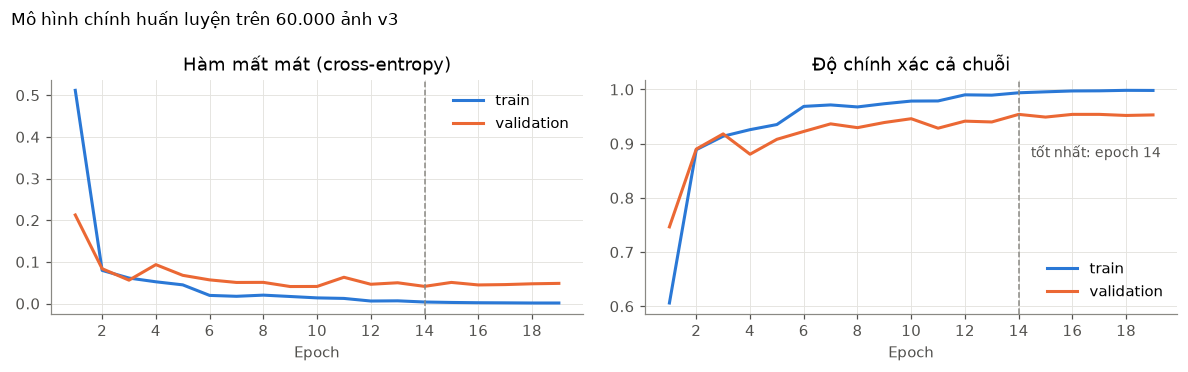

,số epoch,thời gian huấn luyện (phút),val_seq_acc tốt nhất,Độ chính xác cả chuỗi,CER,Độ chính xác độ dài,R² (cách B),NSE (cách B),MAE (cách B),RMSE (cách B)
dữ liệu train (v3),,,,,,,,,,
20.000 ảnh,22,23.4104,0.930,0.9410,0.0118,0.996,0.9695,0.9692,0.0526,0.5036
60.000 ảnh,19,62.1962,0.954,0.9665,0.0063,0.998,0.9843,0.9843,0.0272,0.3601


Theo độ dài (cách A), mô hình 60.000 ảnh:


,số ảnh,seq_acc,R2,NSE,MAE,RMSE
độ dài,,,,,,
3,308,0.9935,0.9908,0.9907,2,28
4,328,0.9817,0.9939,0.9939,13,221
5,354,0.9689,0.9667,0.9661,613,"5,372"
6,310,0.9452,0.4009,-0.5682,"26,518","361,951"
7,343,0.9621,0.9788,0.9787,"34,756","423,119"
8,357,0.9496,0.9869,0.9869,"288,445","3,414,248"


In [36]:
if RUN_EXPERIMENTS:
    model_big, history_big = train_or_load("main_v3big_seed42", lambda: Img2Seq(True, True), version="v3big")
    plot_history(history_big, "Mô hình chính huấn luyện trên 60.000 ảnh v3", os.path.join(FIG_DIR, "main_v3big_learning_curves.png"))
    pred_big = greedy_decode(model_big, test["X"])
    big_rows = []
    for label, history, pred in [("20.000 ảnh", main_history, pred_greedy), ("60.000 ảnh", history_big, pred_big)]:
        s = evaluate(test["labels"], pred)
        big_rows.append({"dữ liệu train (v3)": label, "số epoch": len(history["loss"]),
                         "thời gian huấn luyện (phút)": history["train_time_s"] / 60,
                         "val_seq_acc tốt nhất": max(history["val_seq_acc"]),
                         **{METRIC_NAMES[k]: s[k] for k in s}})
    big_table = pd.DataFrame(big_rows).set_index("dữ liệu train (v3)")
    big_table.to_csv(os.path.join(RESULT_DIR, "v3_20k_vs_60k.csv"))
    display(big_table.round(4))
    print("Theo độ dài (cách A), mô hình 60.000 ảnh:")
    display(report_by_length(test["labels"], pred_big).style.format(
        {"số ảnh": "{:.0f}", "seq_acc": "{:.4f}", "R2": "{:.4f}", "NSE": "{:.4f}", "MAE": "{:,.0f}", "RMSE": "{:,.0f}"}))

## 13. Tăng cường dữ liệu mạnh hơn

Đường học ở mục 4 cho thấy mô hình học vẹt: độ chính xác cả chuỗi trên train gần 100%, trên validation khoảng 93%. Mục 12 chống học vẹt bằng cách sinh thêm ảnh. Mục này thử cách thứ hai của chương 5.3: giữ nguyên 20.000 ảnh nhưng biến đổi mạnh hơn mỗi lần lấy batch. Ngoài đổi độ sáng và thêm nhiễu như cũ, mỗi ảnh còn được:
- co giãn cả chuỗi 85–110% (chiều ngang dao động thêm ±10%), không để nét chữ ra ngoài khung;
- nghiêng cả chuỗi (shear ±0,15);
- dịch ngang −2 đến +6 pixel, dịch dọc ±2 pixel;
- làm đậm nét (20% số ảnh).

Nhãn giữ nguyên. Kiến trúc, siêu tham số, dữ liệu và seed giống hệt mô hình chính; chỉ khác hàm tăng cường.

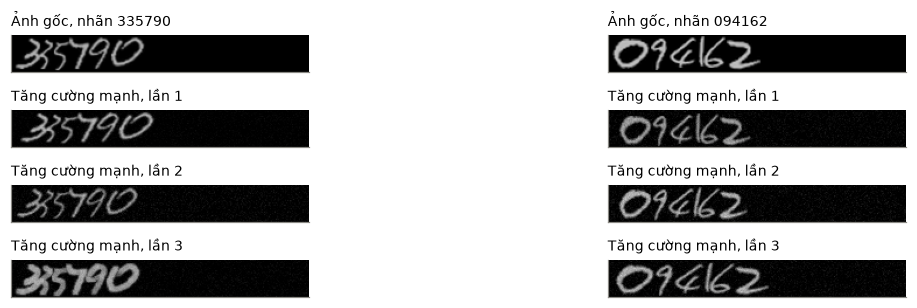

In [37]:
from PIL import ImageFilter


def augment_strong(X, rng):
    out = np.zeros_like(X)
    for k, a in enumerate(X):
        cols, rows = np.flatnonzero(a.max(axis=0) > 0), np.flatnonzero(a.max(axis=1) > 0)
        if len(cols) == 0:
            continue
        x0, wi = cols.min(), cols.max() - cols.min() + 1                  # mép trái và bề rộng phần có nét
        cy, hi = (rows.min() + rows.max()) / 2, rows.max() - rows.min() + 1
        sy = min(rng.uniform(0.85, 1.1), (IMG_H - 4) / hi)               # co giãn, không cho nét ra ngoài khung
        sx = min(sy * rng.uniform(0.9, 1.1), (IMG_W - 14) / wi)
        shear = rng.uniform(-0.15, 0.15)
        dx, dy = rng.uniform(-2, 6), rng.uniform(-2, 2)
        # Biến đổi thuận q = M (p - c) + c + d, với M = nghiêng x co giãn, c = (mép trái, giữa dòng chữ).
        # PIL cần ánh xạ ngược: điểm q của ảnh mới lấy giá trị ở p = M^-1 (q - c - d) + c của ảnh cũ.
        M = np.array([[1, shear], [0, 1]]) @ np.diag([sx, sy])
        M_inv = np.linalg.inv(M)
        c = np.array([x0, cy])
        offset = c - M_inv @ (c + np.array([dx, dy]))
        img = Image.fromarray(a).transform((IMG_W, IMG_H), Image.Transform.AFFINE,
                                           (M_inv[0, 0], M_inv[0, 1], offset[0], M_inv[1, 0], M_inv[1, 1], offset[1]),
                                           resample=Image.Resampling.BILINEAR, fillcolor=0)
        if rng.random() < 0.2:
            img = img.filter(ImageFilter.MaxFilter(3))                  # làm đậm nét
        out[k] = np.asarray(img)
    return augment(out, rng)                                           # thêm đổi độ sáng và nhiễu như cũ


rng = np.random.default_rng(1)
d = data["v3", "train"]
fig, axes = plt.subplots(4, 2, figsize=(11, 2.9))
for col in range(2):
    axes[0, col].imshow(d["X"][col], cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(f"Ảnh gốc, nhãn {d['labels'][col]}", fontsize=9, loc="left")
    for r in range(1, 4):
        axes[r, col].imshow(augment_strong(d["X"][col:col + 1], rng)[0], cmap="gray", vmin=0, vmax=255)
        axes[r, col].set_title(f"Tăng cường mạnh, lần {r}", fontsize=9, loc="left")
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "data_augmentation_strong.png"), bbox_inches="tight")
plt.show()

Đọc trọng số đã huấn luyện: task3_outputs/models/main_v3aug_seed42.weights.h5
  (lần huấn luyện trước: 19 epoch, 22.2 phút; tốt nhất ở epoch 14 với val_seq_acc = 0.9375)


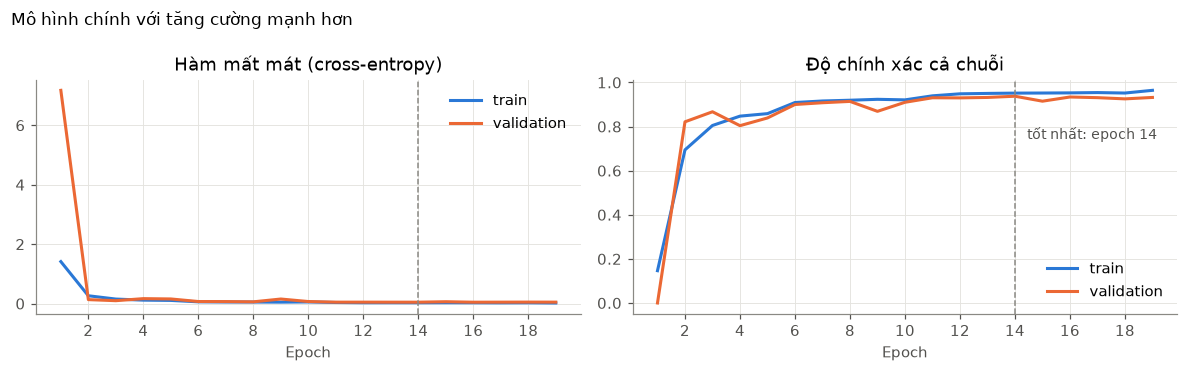

,số epoch,epoch tốt nhất,seq_acc train (epoch tốt nhất),val_seq_acc tốt nhất,thời gian huấn luyện (phút),Độ chính xác cả chuỗi,CER,Độ chính xác độ dài,R² (cách B),NSE (cách B),MAE (cách B),RMSE (cách B)
cách tăng cường,,,,,,,,,,,,
tăng cường cũ: độ sáng + nhiễu,22,17,0.9975,0.9300,23.4104,0.9410,0.0118,0.996,0.9695,0.9692,0.0526,0.5036
tăng cường mạnh hơn,19,14,0.9516,0.9375,22.1591,0.9505,0.0094,0.993,0.9693,0.9691,0.0522,0.5051


In [38]:
if RUN_EXPERIMENTS:
    model_aug, history_aug = train_or_load("main_v3aug_seed42", lambda: Img2Seq(True, True), augment_fn=augment_strong)
    plot_history(history_aug, "Mô hình chính với tăng cường mạnh hơn", os.path.join(FIG_DIR, "main_v3aug_learning_curves.png"))
    pred_aug = greedy_decode(model_aug, test["X"])
    aug_rows = []
    for label, history, pred in [("tăng cường cũ: độ sáng + nhiễu", main_history, pred_greedy),
                                 ("tăng cường mạnh hơn", history_aug, pred_aug)]:
        s = evaluate(test["labels"], pred)
        best = int(np.argmax(history["val_seq_acc"]))
        aug_rows.append({"cách tăng cường": label, "số epoch": len(history["loss"]), "epoch tốt nhất": best + 1,
                         "seq_acc train (epoch tốt nhất)": history["seq_acc"][best],
                         "val_seq_acc tốt nhất": history["val_seq_acc"][best],
                         "thời gian huấn luyện (phút)": history["train_time_s"] / 60,
                         **{METRIC_NAMES[k]: s[k] for k in s}})
    aug_table = pd.DataFrame(aug_rows).set_index("cách tăng cường")
    aug_table.to_csv(os.path.join(RESULT_DIR, "v3_augmentation_comparison.csv"))
    display(aug_table.round(4))

**Nhận xét.**
- Tăng cường mạnh hơn làm mô hình **học vẹt ít hơn hẳn**: ở epoch tốt nhất, độ chính xác cả chuỗi trên train (tính trên ảnh đã tăng cường) là 95,2% so với 93,75% trên validation, khoảng cách chỉ 1,4 điểm, so với 6,75 điểm khi dùng tăng cường cũ.
- Trên test, độ chính xác cả chuỗi tăng 0,95 điểm (94,10% → 95,05%) và CER giảm từ 1,18% xuống 0,94%. Đổi lại, mô hình đọc sai số lượng chữ số nhiều hơn (14 so với 8 ảnh), nên R² và NSE theo cách B gần như không đổi.
- Mục 14 cho thấy mức tăng 0,95 điểm chưa chắc chắn (khoảng tin cậy chạm 0). So với sinh thêm dữ liệu (mục 12, +2,55 điểm), tăng cường mạnh hơn giúp ít hơn nhưng không cần thêm ảnh; hai cách có thể dùng cùng nhau.

## 14. Các chênh lệch có đáng tin không? (khoảng tin cậy bootstrap)

Tập test có 2.000 ảnh, nên mọi con số đều có sai số do chọn mẫu: một tập test khác sinh cùng cách sẽ cho độ chính xác hơi khác. Nhóm ước lượng sai số này bằng **bootstrap**:
- lấy ngẫu nhiên có hoàn lại 2.000 ảnh từ tập test, tính lại chỉ số; lặp 2.000 lần;
- khoảng từ phân vị 2,5% đến 97,5% của 2.000 giá trị là **khoảng tin cậy 95%**.

Khi so hai cách đọc trên cùng tập test, mỗi lần lấy mẫu dùng **cùng các ảnh** cho cả hai rồi tính chênh lệch (bootstrap ghép cặp). Nếu khoảng tin cậy của chênh lệch không chứa 0, chênh lệch đó khó là do may rủi khi chọn ảnh test. Bootstrap chỉ đo sai số do chọn ảnh test; dao động do khởi tạo trọng số được đo riêng bằng 3 seed ở mục 10.

In [39]:
B = 2000
boot_idx = np.random.default_rng(0).integers(0, len(test["labels"]), size=(B, len(test["labels"])))


def correct_of(pred, labels):
    return np.array([t == p for t, p in zip(labels, pred)], dtype=float)


def length_ok_of(pred, labels):
    return np.array([len(t) == len(p) for t, p in zip(labels, pred)], dtype=float)


def ci95(values):
    return np.percentile(values, [2.5, 97.5])


# Khoảng tin cậy của các chỉ số mô hình chính
ok_main = correct_of(pred_greedy, test["labels"])
edits = np.array([metrics.cer([t], [p]) * len(t) for t, p in zip(test["labels"], pred_greedy)])
n_digits = np.array([len(t) for t in test["labels"]], dtype=float)
boot_rows = [{"chỉ số": "Mô hình chính: độ chính xác cả chuỗi", "giá trị": ok_main.mean(),
              "khoảng tin cậy 95%": ci95(ok_main[boot_idx].mean(axis=1))},
             {"chỉ số": "Mô hình chính: CER", "giá trị": edits.sum() / n_digits.sum(),
              "khoảng tin cậy 95%": ci95(edits[boot_idx].sum(axis=1) / n_digits[boot_idx].sum(axis=1))}]
boot_rows = [{**r, "khoảng tin cậy 95%": f"{r['khoảng tin cậy 95%'][0]:.2%} – {r['khoảng tin cậy 95%'][1]:.2%}",
              "giá trị": f"{r['giá trị']:.2%}"} for r in boot_rows]
display(pd.DataFrame(boot_rows).set_index("chỉ số"))

# Chênh lệch độ chính xác cả chuỗi giữa hai cách đọc trên cùng 2.000 ảnh test v3 (bootstrap ghép cặp)
SEQ, LEN = "đọc đúng cả chuỗi", "đúng độ dài"
pairs = [("Beam search k = 3 so với greedy", pred_beam[3], pred_greedy, SEQ, None)]
if RUN_EXPERIMENTS:
    no_att = preds_by_model["CNN + BiLSTM + LSTM decoder"]
    pairs += [("Mô hình chính so với bỏ attention", pred_greedy, no_att, SEQ, None),
              ("Mô hình chính so với bỏ attention, chỉ chuỗi 8 chữ số", pred_greedy, no_att, SEQ, lengths_test == 8),
              ("Mô hình chính so với bỏ BiLSTM", pred_greedy, preds_by_model["CNN + LSTM decoder + Attention"], SEQ, None),
              ("Mô hình chính so với nhiều đầu softmax", pred_greedy, preds_by_model["CNN + nhiều đầu softmax"], SEQ, None),
              ("Gộp 3 seed so với seed 42", pred_ens, pred_greedy, SEQ, None),
              ("60.000 ảnh train so với 20.000 ảnh", pred_big, pred_greedy, SEQ, None),
              ("Tăng cường mạnh hơn so với tăng cường cũ", pred_aug, pred_greedy, SEQ, None)]
    if ("train v2", "v3") in cross_preds:
        pairs += [("Học trên v3 so với học trên v2 (cùng test v3)", pred_greedy, cross_preds["train v2", "v3"], SEQ, None),
                  ("Học trên v3 so với học trên v2 (cùng test v3)", pred_greedy, cross_preds["train v2", "v3"], LEN, None)]
diff_rows = []
for name, pred_a, pred_b, metric, subset in pairs:
    score = correct_of if metric == SEQ else length_ok_of
    keep = np.arange(len(test["labels"])) if subset is None else np.flatnonzero(subset)
    a, b = score(pred_a, test["labels"])[keep], score(pred_b, test["labels"])[keep]
    idx = boot_idx if subset is None else np.random.default_rng(1).integers(0, len(keep), size=(B, len(keep)))
    lo, hi = ci95((a[idx] - b[idx]).mean(axis=1))
    diff_rows.append({"so sánh": name, "chỉ số": metric, "số ảnh": len(keep), "chênh lệch (điểm %)": (a.mean() - b.mean()) * 100,
                      "khoảng tin cậy 95% (điểm %)": f"{lo * 100:+.2f} đến {hi * 100:+.2f}",
                      "khác 0 rõ ràng?": "có" if lo > 0 or hi < 0 else "chưa chắc",
                      "số ảnh chỉ A đúng": int(((a == 1) & (b == 0)).sum()), "số ảnh chỉ B đúng": int(((a == 0) & (b == 1)).sum())})
diff_table = pd.DataFrame(diff_rows).set_index(["so sánh", "chỉ số"])
diff_table.to_csv(os.path.join(RESULT_DIR, "bootstrap_differences.csv"))
diff_table.style.format({"chênh lệch (điểm %)": "{:+.2f}"})

,giá trị,khoảng tin cậy 95%
chỉ số,,
Mô hình chính: độ chính xác cả chuỗi,94.10%,92.95% – 95.05%
Mô hình chính: CER,1.18%,0.97% – 1.41%


,,số ảnh,chênh lệch (điểm %),khoảng tin cậy 95% (điểm %),khác 0 rõ ràng?,số ảnh chỉ A đúng,số ảnh chỉ B đúng
so sánh,chỉ số,,,,,,
Beam search k = 3 so với greedy,đọc đúng cả chuỗi,2000,+0.15,+0.00 đến +0.35,chưa chắc,3,0
Mô hình chính so với bỏ attention,đọc đúng cả chuỗi,2000,+0.80,-0.25 đến +1.85,chưa chắc,63,47
"Mô hình chính so với bỏ attention, chỉ chuỗi 8 chữ số",đọc đúng cả chuỗi,357,+4.76,+1.68 đến +7.84,có,24,7
Mô hình chính so với bỏ BiLSTM,đọc đúng cả chuỗi,2000,+14.60,+12.70 đến +16.40,có,336,44
Mô hình chính so với nhiều đầu softmax,đọc đúng cả chuỗi,2000,+17.35,+15.45 đến +19.15,có,385,38
Gộp 3 seed so với seed 42,đọc đúng cả chuỗi,2000,+1.25,+0.55 đến +1.95,có,38,13
60.000 ảnh train so với 20.000 ảnh,đọc đúng cả chuỗi,2000,+2.55,+1.60 đến +3.55,có,71,20
Tăng cường mạnh hơn so với tăng cường cũ,đọc đúng cả chuỗi,2000,+0.95,-0.05 đến +2.00,chưa chắc,60,41
Học trên v3 so với học trên v2 (cùng test v3),đọc đúng cả chuỗi,2000,+0.40,-0.70 đến +1.45,chưa chắc,66,58


**Nhận xét.**
- **Chắc chắn** (khoảng tin cậy không chứa 0): phần RNN so với nhiều đầu softmax (+17,35 điểm), BiLSTM (+14,60), sinh thêm dữ liệu lên 60.000 ảnh (+2,55), gộp 3 seed (+1,25). Attention giúp chắc chắn ở chuỗi 8 chữ số (+4,76 điểm, khoảng tin cậy từ +1,7 đến +7,8). Mô hình học trên v3 đếm đúng số chữ số hơn mô hình học trên v2 (+0,85 điểm độ chính xác độ dài, từ +0,40 đến +1,35).
- **Chưa chắc** (khoảng tin cậy chứa 0): beam search (+0,15), attention tính trên cả tập test (+0,80), tăng cường mạnh hơn (+0,95), học trên v3 so với v2 xét độ chính xác cả chuỗi (+0,40). Các chênh lệch này có thể là thật, nhưng 2.000 ảnh test chưa đủ để khẳng định.
- Vì vậy nhóm chỉ kết luận chắc chắn ở nhóm thứ nhất; với nhóm thứ hai, nhóm nêu xu hướng kèm khoảng tin cậy.

## 15. Đọc một ảnh bất kỳ (dùng cho demo)

Ảnh chụp chữ viết thật thường là chữ tối trên giấy sáng và có kích thước tuỳ ý. Hàm `prepare_image` đưa ảnh về đúng dạng dữ liệu huấn luyện: chuyển ảnh xám, đảo màu nếu nền sáng, cắt sát vùng có nét chữ, co về cao 24 pixel (giữ tỉ lệ), đặt lên nền đen 32 × 256. Ví dụ dưới đây lấy một ảnh test, đảo thành chữ đen nền trắng, phóng to và thêm lề để giả lập một ảnh chụp, rồi cho mô hình đọc.

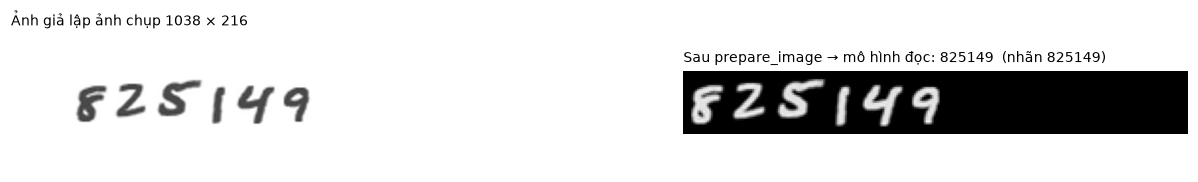

In [40]:
def prepare_image(image):
    # image: đường dẫn file hoặc mảng numpy. Trả về mảng uint8 (32, 256) giống dữ liệu huấn luyện.
    img = Image.open(image) if isinstance(image, str) else Image.fromarray(np.asarray(image).astype(np.uint8))
    a = np.asarray(img.convert("L"), dtype=np.float32)
    if np.median(a) > 127:                    # nền sáng, chữ tối -> đảo màu cho giống MNIST
        a = 255 - a
    a = np.clip(a - np.median(a), 0, None)    # bỏ mức sáng của nền
    a = a / max(a.max(), 1) * 255
    ys, xs = np.nonzero(a > 60)               # cắt sát vùng có nét chữ
    a = a[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = a.shape
    scale = min(24 / h, (IMG_W - 8) / w)      # cao 24 pixel, không vượt quá bề rộng 256
    new_w, new_h = max(1, round(w * scale)), max(1, round(h * scale))
    small = np.asarray(Image.fromarray(a.astype(np.uint8)).resize((new_w, new_h), Image.Resampling.LANCZOS))
    canvas = np.zeros((IMG_H, IMG_W), np.uint8)
    top = (IMG_H - new_h) // 2
    canvas[top:top + new_h, 4:4 + new_w] = small
    return canvas


def read_digits(model, image, beam_size=1):
    x = prepare_image(image)[None]
    return greedy_decode(model, x)[0] if beam_size == 1 else beam_search(model, x, beam_size)[0]


best_model = model_big if RUN_EXPERIMENTS else main_model     # mô hình dùng cho demo
i = int(np.flatnonzero(lengths_test == 6)[0])
photo = 255 - np.pad(test["X"][i], ((20, 20), (30, 60)))                              # chữ đen trên nền trắng
photo = np.asarray(Image.fromarray(photo).resize((photo.shape[1] * 3, photo.shape[0] * 3), Image.Resampling.BICUBIC))
fig, axes = plt.subplots(1, 2, figsize=(11, 1.6), gridspec_kw={"width_ratios": [1.3, 1]})
axes[0].imshow(photo, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"Ảnh giả lập ảnh chụp {photo.shape[1]} × {photo.shape[0]}", fontsize=9, loc="left")
axes[1].imshow(prepare_image(photo), cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Sau prepare_image → mô hình đọc: {read_digits(best_model, photo)}  (nhãn {test['labels'][i]})",
                  fontsize=9, loc="left")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 16. Tổng hợp kết quả

In [41]:
summary = {"data": "v3: mỗi ảnh ghép chữ số của cùng một người viết",
           "main_test_v3_greedy": main_scores,
           "main_test_v3_by_length_approachA": by_length.to_dict(orient="index"),
           "main_test_v3_by_writer_group": group_table.to_dict(orient="index"),
           "confidence_coverage": coverage_table.to_dict(orient="index"),
           "E7_decoding": decode_table.to_dict(orient="index")}
if RUN_EXPERIMENTS:
    summary["E6_architectures"] = compare_table.to_dict(orient="index")
    summary["seeds"] = seed_table.to_dict(orient="index")
    if cross_rows:
        summary["v2_vs_v3"] = {" / ".join(k): v for k, v in cross_table.to_dict(orient="index").items()}
    summary["v3_20k_vs_60k"] = big_table.to_dict(orient="index")
    summary["ensemble_3_seeds"] = ens_table.to_dict(orient="index")
    summary["strong_augmentation"] = aug_table.to_dict(orient="index")
summary["bootstrap_differences"] = {" / ".join(k): v for k, v in diff_table.to_dict(orient="index").items()}
with open(os.path.join(RESULT_DIR, "task3_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=float)
print("Đã lưu kết quả vào", RESULT_DIR)
print(sorted(os.listdir(RESULT_DIR)))
print(sorted(os.listdir(FIG_DIR)))

Đã lưu kết quả vào task3_outputs/results
['E6_accuracy_by_length.csv', 'E6_architecture_comparison.csv', 'E7_greedy_vs_beam.csv', 'bootstrap_differences.csv', 'main_v3_confidence_coverage.csv', 'main_v3_ensemble.csv', 'main_v3_test_by_length_approachA.csv', 'main_v3_test_predictions.csv', 'main_v3_three_seeds.csv', 'task3_summary.json', 'v2_vs_v3_cross_test.csv', 'v3_20k_vs_60k.csv', 'v3_augmentation_comparison.csv']
['E6_architecture_comparison.png', 'attention_examples.png', 'confidence_coverage.png', 'data_augmentation.png', 'data_augmentation_strong.png', 'data_length_digit_distribution.png', 'data_padding.png', 'data_samples.png', 'data_width_by_length.png', 'data_writer_comparison.png', 'digit_confusion_matrix.png', 'error_examples.png', 'length_error_examples.png', 'main_learning_curves.png', 'main_v3aug_learning_curves.png', 'main_v3big_learning_curves.png', 'model_architecture.png']


## 17. Kết luận

1. **Dữ liệu.** Theo góp ý của giảng viên, mỗi ảnh ghép 3–8 chữ số MNIST của **cùng một người viết** (mã người viết theo QMNIST); train, validation và test dùng ba nhóm người viết khác nhau.
2. **Mô hình chính** (CNN kiểu VGG + BiLSTM + LSTM decoder có attention Bahdanau, 2,3 triệu tham số), học trên 20.000 ảnh v3, đọc đúng hoàn toàn **94,10%** trong 2.000 ảnh test (khoảng tin cậy 95%: 92,95–95,05%; 3 seed: 94,35 ± 0,22%), CER 1,18%, đọc đúng số lượng chữ số 99,6%. Theo cách B: R² = 0,970, NSE = 0,969, MAE = 0,053, RMSE = 0,504.
3. **Sinh thêm dữ liệu giúp nhiều nhất:** với 60.000 ảnh train, độ chính xác cả chuỗi lên **96,65%** (+2,55 điểm, chắc chắn theo bootstrap), CER 0,63%, R² = NSE = 0,984. Đây là mô hình dùng cho demo.
4. **Hai cách nâng cấp khác:**
   - Gộp 3 seed (lấy trung bình xác suất ở mỗi bước) đạt 95,35% (+1,25 điểm so với seed 42, chắc chắn), đổi lại đọc chậm gấp khoảng 3 lần.
   - Tăng cường dữ liệu mạnh hơn giảm học vẹt rõ (khoảng cách train–validation từ 6,75 xuống 1,4 điểm); độ chính xác test tăng 0,95 điểm nhưng chưa chắc chắn.
5. **Thí nghiệm E6, BiLSTM và phần RNN đóng góp lớn nhất:**
   - Bỏ BiLSTM: còn 79,50% (−14,6 điểm), vì mỗi cột CNN không biết mình là chữ số thứ mấy và attention khó tìm đúng chữ số tiếp theo.
   - Mô hình mốc không có RNN (9 đầu softmax): 76,75%, chỉ 39,5% ở chuỗi 8 chữ số.
   - Bỏ attention: còn 93,30%. Trên cả tập chênh lệch chưa chắc, nhưng ở chuỗi 8 chữ số attention giúp rõ (86,8% → 91,6%), đúng lý do attention ra đời.
6. **Thí nghiệm E7:** beam search (k = 3, 5) chỉ sửa được 3/2.000 ảnh (+0,15 điểm, chưa chắc). Mô hình rất tự tin (98,1% số bước có xác suất trên 0,99) và các chữ số độc lập nhau, nên greedy search là đủ.
7. **Mô hình giải thích được:** ở 100% ảnh đọc đúng, tâm attention trượt dần từ trái sang phải theo từng chữ số; bước `<eos>` nhìn vào chỗ hết chữ.
8. **Ghép một người viết (v3) hay nhiều người viết (v2):** trên test v3, mô hình học trên v3 đếm đúng số chữ số hơn (8 so với 25 ảnh sai độ dài, chắc chắn); độ chính xác cả chuỗi hơn 0,40 điểm (chưa chắc).
9. **Lỗi còn lại:**
   - 110/118 lỗi là đọc nhầm một chữ số, hay gặp 8 → 9, 4 → 9, 8 → 2, 5 → 3; chữ số 8 khó đọc nhất.
   - Chữ học sinh khó đọc hơn chữ nhân viên (93,3% so với 95,6%), nhất là ở chuỗi dài.
   - Đọc kèm độ tự tin: chuyển 10% ảnh kém tự tin nhất cho người kiểm tra thì độ chính xác trên phần còn lại lên 98,1%; nhưng 55% ảnh sai là sai một cách tự tin nên không lọc hết được.
10. **Hạn chế và việc tiếp theo:** mô hình mới chỉ được đánh giá trên ảnh tổng hợp. Chữ viết tay thật có thể khác (khoảng cách không đều, viết tách nhóm, nét bút khác), nên bước tiếp theo là thí nghiệm E8 trong proposal: đọc thử ảnh nhóm tự viết bằng hàm `read_digits` (mục 15).